In [280]:
import sys
import os
from typing import NamedTuple
import math
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import pickle

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_worm import artificializer
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import bom
from models import hgm

In [281]:
import importlib
importlib.reload(artificializer)
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

# Functions

In [282]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

In [283]:
def separate_losses(file_ids, columns, models_spn_man_rec_res_pres):
	models_spn = [
		[
			pd.DataFrame(data=np.array(split[0])[None], columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	models_man = [
		[
			pd.DataFrame(data=np.array(split[1]), columns=[f'M{i}' for i in range(np.array(split[1]).shape[1])]) for split in models_spn_man_rec_res_pres[i]
		] for i in range(len(file_ids))
	]
	(models_rec,
	 models_res,
	 models_pres) = tuple(
		[
			[
				pd.DataFrame(data=np.array(split[m]), columns=columns[i]) for split in models_spn_man_rec_res_pres[i]
			] for i in range(len(file_ids))
		] for m in [2, 3, 4]
	)
	return models_spn, models_man, models_rec, models_res, models_pres

In [284]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

# read & prep

In [285]:
default_hyperparameters = {
	'dimensions': 1,
	'loss1_lambda': 0.0,
	'loss2_lambda': 1.0 - 0.0,
	'w1_reg_lambda': 0.0,
	'w2_reg_lambda': 0.0,
}

ll = f'll{int(default_hyperparameters['loss1_lambda'] * 100):02d}'

with open('../sweep/hyperparams.pkl', 'rb') as f:
    swept_hyperparameters = pickle.load(f)

bom_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	'w1_reg_lambda': swept_hyperparameters[ll]['bom']['w1_reg_lambda']['mean']['geometric'],
}
hgm_reg_lamdas = {
	# 'w1_reg_lambda': default_hyperparameters['w1_reg_lambda'],
	# 'w2_reg_lambda': default_hyperparameters['w2_reg_lambda'],
	'w1_reg_lambda': swept_hyperparameters[ll]['hgm']['w1_reg_lambda']['mean']['geometric'],
	'w2_reg_lambda': swept_hyperparameters[ll]['hgm']['w2_reg_lambda']['mean']['geometric'],
}

In [286]:
artificial = False
if artificial:
	dims_generation = 2
	weights = (0.1, -0.25)


gcamp = True
# read_ids_gcamp = list(range(0, 33+1))
# read_ids_gcamp = [0,   # minrevs
# 				  1,   # minswitch
# 				  7,   # maxswitch
# 				  11,  # median
# 				  12,  # maxrevs
# 				  17,  # mean
# 				  19,  # paper
# 				  21]  # clean
read_ids_gcamp = [19]
plot_id_gcamp = 19


gfp = True
if gfp:
	# read_ids_gfp = list(range(0, 7+1))
	# read_ids_gfp = [2, 4, 6]
	read_ids_gfp = [2]
	plot_id_gfp = 2

In [287]:
# read

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(file_ids_gcamp, filenames_gcamp,
 traces_gcamp,
 continuous_behaviors_gcamp,
 discrete_states_gcamp, eigenworms_gcamp,
 kymographs_gcamp) = read_utils.get_data(path, read_ids_gcamp)

# clear nan values
for i in range(len(file_ids_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)

	traces_gcamp[i] = traces_gcamp[i][mask]
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids_gcamp)):
	traces_gcamp[i].columns = pd.Index([
		f'{file_ids_gcamp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gcamp[i].columns, traces_gcamp[i].columns == ''))
	])


if gfp:
	path = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
	(file_ids_gfp, filenames_gfp,
	 traces_gfp,
	 continuous_behaviors_gfp,
	 discrete_states_gfp, eigenworms_gfp,
	 kymographs_gfp) = read_utils.get_data(path, read_ids_gfp)

	# clear nan values
	for i in range(len(file_ids_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)

		traces_gfp[i] = traces_gfp[i][mask]
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	# naive ID unknown neurons
	for i in range(len(file_ids_gfp)):
		traces_gfp[i].columns = pd.Index([
			f'{file_ids_gfp[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces_gfp[i].columns, traces_gfp[i].columns == ''))
		])

In [288]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_n_traces = ['AVAR', 'ALA',
					  'SMDDL', 'RMDDR', 'SMDDR', 'VB02', 'DB01',
					  'SIADR', 'DD01']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

plot_idx_gcamp = file_ids_gcamp.index(plot_id_gcamp)
plot_idx_gfp = file_ids_gfp.index(plot_id_gfp)

selection_n = [label for label in selection_n if label in traces_gcamp[plot_idx_gcamp].columns]
selection_n_traces_gcamp = [label for label in selection_n_traces if label in traces_gcamp[file_ids_gcamp.index(plot_id_gcamp)].columns]
if gfp:
	selection_n_traces_gfp = [label for label in selection_n_traces if label in traces_gfp[file_ids_gfp.index(plot_id_gfp)].columns]
# discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]

In [289]:
# generate

if artificial:
	plot_id_art = plot_id_gcamp

	file_ids_art = list()
	filenames_art = list()

	discrete_states_art = list()
	eigenworms_art = list()

	modes_art = list()
	traces_reconstructed_art = list()
	traces_residual_art = list()
	traces_art = list()

	for i in range(len(file_ids_gcamp)):
		(filename_art,
		 neural_modes_art_,
		 traces_reconstructed_art_,
		 traces_residual_art_,
		 traces_art_,
		 params_art_,
		 params_cca_art_) = artificializer.artificialize(weights, hgm,
														 filenames_gcamp[i],
														 traces_gcamp[i].columns,
														 eigenworms_gcamp[i],
														 [ds[selection_bhl] for ds in discrete_states_gcamp][i],
														 n_dimensions=dims_generation)
		filenames_art.append(filename_art)

		modes_art.append(neural_modes_art_)
		traces_reconstructed_art.append(traces_reconstructed_art_)
		traces_residual_art.append(traces_residual_art_)
		traces_art.append(traces_art_)

		file_ids_art.append(file_ids_gcamp[i])

		discrete_states_art.append(discrete_states_gcamp[i].copy())
		eigenworms_art.append(eigenworms_gcamp[i].copy())

	plot_idx_art = file_ids_art.index(plot_id_art)

# read models

In [290]:
organism = 'worm-2025-fieseler'

if gcamp:
	bom_load_name_gcamp = os.path.join(organism, ll, f'bom_gcamp_w1-{bom_reg_lamdas['w1_reg_lambda']:.2E}')
	hgm_load_name_gcamp = os.path.join(organism, ll, f'hgm_gcamp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.2E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.2E}')

if gfp:
	bom_load_name_gfp = os.path.join(organism, ll, f'bom_gfp_w1-{bom_reg_lamdas['w1_reg_lambda']:.2E}')
	hgm_load_name_gfp = os.path.join(organism, ll, f'hgm_gfp_w1-{hgm_reg_lamdas['w1_reg_lambda']:.2E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.2E}')

if artificial:
	bom_load_name_art = os.path.join(organism, ll, f'bom_art_w1-{bom_reg_lamdas['w1_reg_lambda']:.2E}')
	hgm_load_name_art = os.path.join(organism, ll, f'hgm_art_w1-{hgm_reg_lamdas['w1_reg_lambda']:.2E}_w2-{hgm_reg_lamdas['w2_reg_lambda']:.2E}')

In [291]:
if gcamp:
	boms_params_gcamp = train_utils.load_params(bom_load_name_gcamp, filenames_gcamp)

	boms_losses_gcamp = train_utils.load_losses(bom_load_name_gcamp, filenames_gcamp)
	boms_losses_train_gcamp = [losses[0] for losses in boms_losses_gcamp]
	boms_man_losses_train_gcamp = [losses[1] for losses in boms_losses_gcamp]
	boms_res_losses_train_gcamp = [losses[2] for losses in boms_losses_gcamp]
	boms_mpe_losses_train_gcamp = [losses[3] for losses in boms_losses_gcamp]
	boms_losses_test_gcamp = [losses[4] for losses in boms_losses_gcamp]
	boms_man_losses_test_gcamp = [losses[5] for losses in boms_losses_gcamp]
	boms_res_losses_test_gcamp = [losses[6] for losses in boms_losses_gcamp]
	boms_mpe_losses_test_gcamp = [losses[7] for losses in boms_losses_gcamp]

	hgms_params_gcamp = train_utils.load_params(hgm_load_name_gcamp, filenames_gcamp)

	hgms_losses_gcamp = train_utils.load_losses(hgm_load_name_gcamp, filenames_gcamp)
	hgms_losses_train_gcamp = [losses[0] for losses in hgms_losses_gcamp]
	hgms_man_losses_train_gcamp = [losses[1] for losses in hgms_losses_gcamp]
	hgms_res_losses_train_gcamp = [losses[2] for losses in hgms_losses_gcamp]
	hgms_mpe_losses_train_gcamp = [losses[3] for losses in hgms_losses_gcamp]
	hgms_losses_test_gcamp = [losses[4] for losses in hgms_losses_gcamp]
	hgms_man_losses_test_gcamp = [losses[5] for losses in hgms_losses_gcamp]
	hgms_res_losses_test_gcamp = [losses[6] for losses in hgms_losses_gcamp]
	hgms_mpe_losses_test_gcamp = [losses[7] for losses in hgms_losses_gcamp]


if gfp:
	boms_params_gfp = train_utils.load_params(bom_load_name_gfp, filenames_gfp)

	boms_losses_gfp = train_utils.load_losses(bom_load_name_gfp, filenames_gfp)
	boms_losses_train_gfp = [losses[0] for losses in boms_losses_gfp]
	boms_man_losses_train_gfp = [losses[1] for losses in boms_losses_gfp]
	boms_res_losses_train_gfp = [losses[2] for losses in boms_losses_gfp]
	boms_mpe_losses_train_gfp = [losses[3] for losses in boms_losses_gfp]
	boms_losses_test_gfp = [losses[4] for losses in boms_losses_gfp]
	boms_man_losses_test_gfp = [losses[5] for losses in boms_losses_gfp]
	boms_res_losses_test_gfp = [losses[6] for losses in boms_losses_gfp]
	boms_mpe_losses_test_gfp = [losses[7] for losses in boms_losses_gfp]

	hgms_params_gfp = train_utils.load_params(hgm_load_name_gfp, filenames_gfp)

	hgms_losses_gfp = train_utils.load_losses(hgm_load_name_gfp, filenames_gfp)
	hgms_losses_train_gfp = [losses[0] for losses in hgms_losses_gfp]
	hgms_man_losses_train_gfp = [losses[1] for losses in hgms_losses_gfp]
	hgms_res_losses_train_gfp = [losses[2] for losses in hgms_losses_gfp]
	hgms_mpe_losses_train_gfp = [losses[3] for losses in hgms_losses_gfp]
	hgms_losses_test_gfp = [losses[4] for losses in hgms_losses_gfp]
	hgms_man_losses_test_gfp = [losses[5] for losses in hgms_losses_gfp]
	hgms_res_losses_test_gfp = [losses[6] for losses in hgms_losses_gfp]
	hgms_mpe_losses_test_gfp = [losses[7] for losses in hgms_losses_gfp]


if artificial:
	boms_params_art = train_utils.load_params(bom_load_name_art, filenames_art)

	boms_losses_art = train_utils.load_losses(bom_load_name_art, filenames_art)
	boms_losses_train_art = [losses[0] for losses in boms_losses_art]
	boms_man_losses_train_art = [losses[1] for losses in boms_losses_art]
	boms_res_losses_train_art = [losses[2] for losses in boms_losses_art]
	boms_mpe_losses_train_art = [losses[3] for losses in boms_losses_art]
	boms_losses_test_art = [losses[4] for losses in boms_losses_art]
	boms_man_losses_test_art = [losses[5] for losses in boms_losses_art]
	boms_res_losses_test_art = [losses[6] for losses in boms_losses_art]
	boms_mpe_losses_test_art = [losses[7] for losses in boms_losses_art]

	hgms_params_art = train_utils.load_params(hgm_load_name_art, filenames_art)

	hgms_losses_art = train_utils.load_losses(hgm_load_name_art, filenames_art)
	hgms_losses_train_art = [losses[0] for losses in hgms_losses_art]
	hgms_man_losses_train_art = [losses[1] for losses in hgms_losses_art]
	hgms_res_losses_train_art = [losses[2] for losses in hgms_losses_art]
	hgms_mpe_losses_train_art = [losses[3] for losses in hgms_losses_art]
	hgms_losses_test_art = [losses[4] for losses in hgms_losses_art]
	hgms_man_losses_test_art = [losses[5] for losses in hgms_losses_art]
	hgms_res_losses_test_art = [losses[6] for losses in hgms_losses_art]
	hgms_mpe_losses_test_art = [losses[7] for losses in hgms_losses_art]

# artificial

### losses

In [292]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_losses_train_art, boms_losses_train_art,
								  title='art hgm vs bom: train',
								  ylimits=None)

In [293]:
if artificial:
	plot_utils.plot_losses_splits(filenames_art,
								  hgms_losses_test_art, boms_losses_test_art,
								  title='art hgm vs bom: test',
								  ylimits=None)

### predict & score

In [294]:
if artificial:
	splits_art = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_art[i].shape[0]), discrete_states_art[i][['REV']].values)) for i in range(len(file_ids_art))]

In [295]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(boms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values[eval], eigenworms_art[i].values[eval]) for params, (train, eval) in zip(hgms_params_art[i], splits_art[i])
	] for i in range(len(file_ids_art))]

	(boms_spn_art,
	 boms_man_art,
	 boms_rec_art,
	 boms_res_art,
	 boms_pres_art) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art,
	 hgms_man_art,
	 hgms_rec_art,
	 hgms_res_art,
	 hgms_pres_art) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

### performance

In [296]:
if artificial:
	neuron_scores_art = assemble(boms_spn_art, hgms_spn_art)

In [297]:
if artificial:
	plot_utils.plot_performance_plot(neuron_scores_art, None,
									 title='scores for all neurons', limits=(-0.55, 1.1, -0.55, 1.1))

In [298]:
if artificial:
	plot_utils.plot_performance_plot({key: neuron_scores_art[key] for key in neuron_scores_art.keys() if not key[0].isdigit()}, None,
									 title='scores for ID\'d neurons', limits=(-0.55, 1.1, -0.55, 1.1))

### traces

In [299]:
if artificial:
	boms_spn_man_rec_res_pres_art = [[
		bom.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in boms_params_art[i]
	] for i in range(len(file_ids_art))]

	hgms_spn_man_rec_res_pres_art = [[
		hgm.score_fn(params, traces_art[i].values, eigenworms_art[i].values) for params in hgms_params_art[i]
	] for i in range(len(file_ids_art))]

	(boms_spn_art_full,
	 boms_man_art_full,
	 boms_rec_art_full,
	 boms_res_art_full,
	 boms_pres_art_full) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], boms_spn_man_rec_res_pres_art)

	(hgms_spn_art_full,
	 hgms_man_art_full,
	 hgms_rec_art_full,
	 hgms_res_art_full,
	 hgms_pres_art_full) = separate_losses(file_ids_art, [trace.columns for trace in traces_art], hgms_spn_man_rec_res_pres_art)

In [300]:
if artificial:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_rec_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_rec_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
		traces_reconstructed_art[plot_idx_art][selection_n_traces_gcamp],
		discrete_states_art[plot_idx_art][['REV']], label='reversal',
		title=f'{filenames_art[plot_idx_art]} art hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/ART_MAN'

In [301]:
if artificial:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_rec_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_rec_art_full[plot_idx_art][i][selection_n_traces_gcamp] for i in range(splits)],
		traces_residual_art[plot_idx_art][selection_n_traces_gcamp],
		discrete_states_art[plot_idx_art][['REV']], label='reversal',
		title=f'{filenames_art[plot_idx_art]} art hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/ART_RES'

In [302]:
if artificial:
	for i in range(5):
		plot_utils.plot_traces_splits_pairs(
			[hgms_res_art_full[plot_idx_art][i][selection_n_traces_gcamp],
			 hgms_pres_art_full[plot_idx_art][i][selection_n_traces_gcamp]],
			[boms_res_art_full[plot_idx_art][i][selection_n_traces_gcamp],
			 boms_pres_art_full[plot_idx_art][i][selection_n_traces_gcamp]],
			traces_residual_art[plot_idx_art][selection_n_traces_gcamp],
			discrete_states_art[plot_idx_art][['REV']], label='reversal',
			title=f'{filenames_art[plot_idx_art]} split {i} art hgm & bom predictions residuals', ylimits=(-0.5, 0.5), plots_per_row=1,
			save_path=None)  #../../out/plots/f'ART_PRES_S{i}'

 # gcamp

### losses

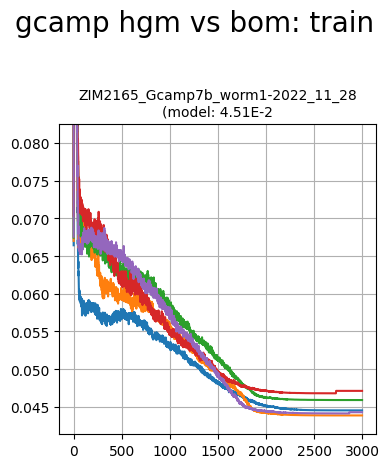

In [303]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_losses_train_gcamp,
								  title='gcamp hgm vs bom: train',
								  ylimits=0.025)

In [304]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: man train',
# 								  filenames_gcamp,
# 								  hgms_man_losses_train_gcamp, boms_man_losses_train_gcamp,
# 								  ylimits=None)

In [305]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: res train',
# 								  filenames_gcamp,
# 								  hgms_res_losses_train_gcamp, boms_res_losses_train_gcamp,
# 								  ylimits=None)

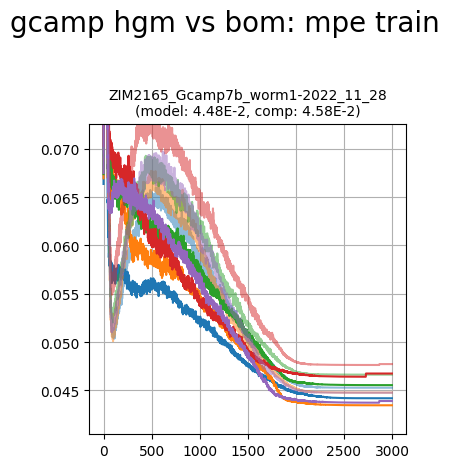

In [306]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_mpe_losses_train_gcamp, boms_mpe_losses_train_gcamp,
								  ylimits=0.03,
								  title='gcamp hgm vs bom: mpe train')

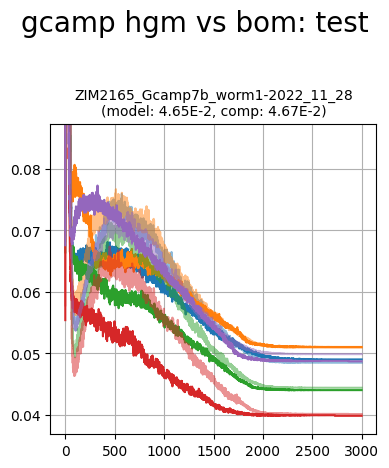

In [307]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_losses_test_gcamp, boms_losses_test_gcamp,
								  title='gcamp hgm vs bom: test',
								  ylimits=0.03)

In [308]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: man test',
# 								  filenames_gcamp,
# 								  hgms_man_losses_test_gcamp, boms_man_losses_test_gcamp,
# 								  ylimits=None)

In [309]:
# if gcamp:
# 	plot_utils.plot_losses_splits('gcamp hgm vs bom: res test',
# 								  filenames_gcamp,
# 								  hgms_res_losses_test_gcamp, boms_res_losses_test_gcamp,
# 								  ylimits=None)

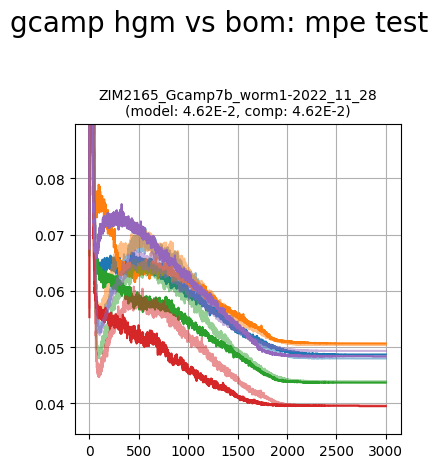

In [310]:
if gcamp:
	plot_utils.plot_losses_splits(filenames_gcamp,
								  hgms_mpe_losses_test_gcamp, boms_mpe_losses_test_gcamp,
								  ylimits=0.05,
								  title='gcamp hgm vs bom: mpe test')

### predict & score

In [311]:
if gcamp:
	splits_gcamp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i][['REV']].values)) for i in range(len(file_ids_gcamp))]

In [312]:
if gcamp:
	boms_spn_man_rec_res_pres_gcamp = [[
		bom.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(boms_params_gcamp[i], splits_gcamp[i])
	] for i in range(len(file_ids_gcamp))]

	hgms_spn_man_rec_res_pres_gcamp = [[
		hgm.score_fn(params, traces_gcamp[i].values[eval], eigenworms_gcamp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gcamp[i], splits_gcamp[i])
	] for i in range(len(file_ids_gcamp))]

	(boms_spn_gcamp,
	 boms_man_gcamp,
	 boms_rec_gcamp,
	 boms_res_gcamp,
	 boms_pres_gcamp) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

	(hgms_spn_gcamp,
	 hgms_man_gcamp,
	 hgms_rec_gcamp,
	 hgms_res_gcamp,
	 hgms_pres_gcamp) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

### performance

In [313]:
if gcamp:
	neuron_scores_gcamp = assemble(boms_spn_gcamp, hgms_spn_gcamp)

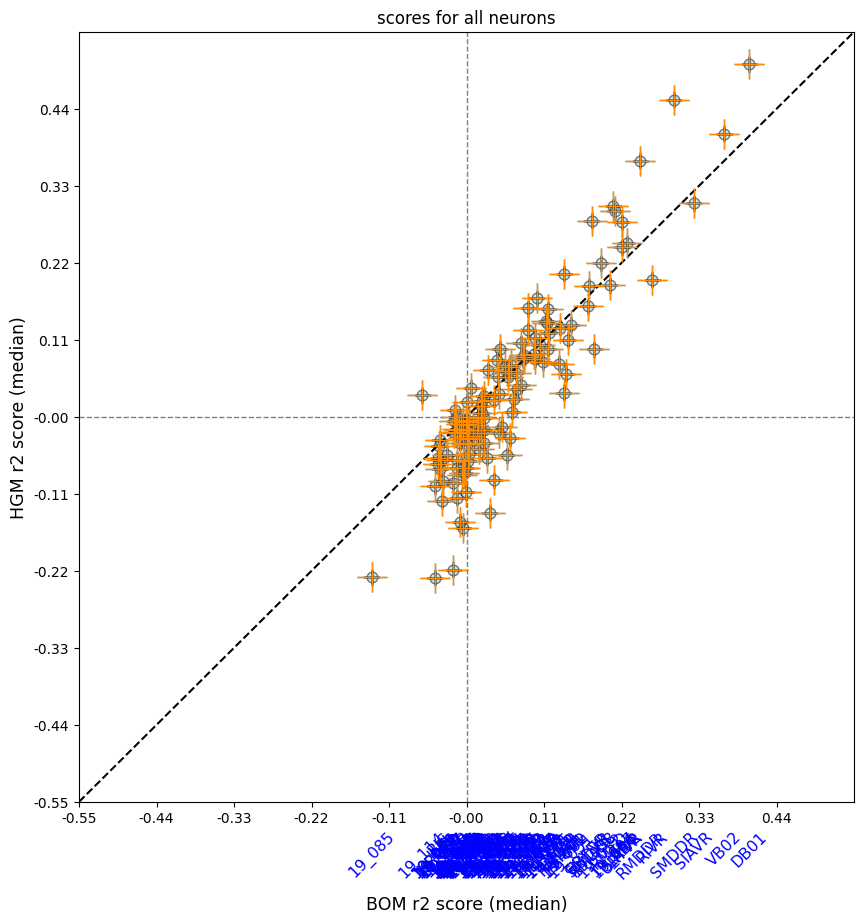

In [314]:
if gcamp:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, None,
		title='scores for all neurons', limits=(-0.55, 0.55, -0.55, 0.55), force_medians=True
	)

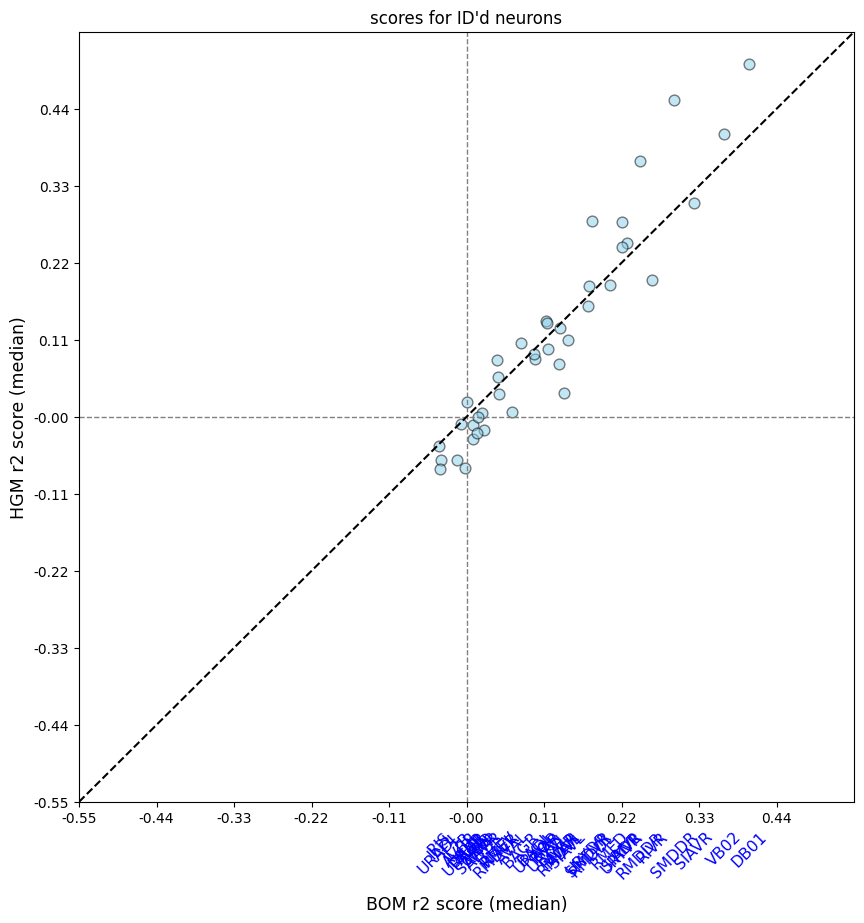

In [315]:
if gcamp:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in neuron_scores_gcamp.keys() if not key[0].isdigit()}, None,
		title='scores for ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55)
	)

### traces

In [316]:
if gcamp:
	boms_spn_man_rec_res_pres_gcamp = [[
		bom.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in boms_params_gcamp[i]
	] for i in range(len(file_ids_gcamp))]

	hgms_spn_man_rec_res_pres_gcamp = [[
		hgm.score_fn(params, traces_gcamp[i].values, eigenworms_gcamp[i].values) for params in hgms_params_gcamp[i]
	] for i in range(len(file_ids_gcamp))]

	(boms_spn_gcamp_full,
	 boms_man_gcamp_full,
	 boms_rec_gcamp_full,
	 boms_res_gcamp_full,
	 boms_pres_gcamp_full) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], boms_spn_man_rec_res_pres_gcamp)

	(hgms_spn_gcamp_full,
	 hgms_man_gcamp_full,
	 hgms_rec_gcamp_full,
	 hgms_res_gcamp_full,
	 hgms_pres_gcamp_full) = separate_losses(file_ids_gcamp, [trace.columns for trace in traces_gcamp], hgms_spn_man_rec_res_pres_gcamp)

In [317]:
if gcamp:
	_, _, traces_cca_rec_gcamp, _, _, _, _, _ = train_utils.get_manifolds_cca(traces_gcamp, discrete_states_gcamp, n_cv=default_hyperparameters['dimensions'], n_pc=0)
	traces_cca_res_gcamp = [pd.DataFrame(data=trace_gcamp.values - trace_cca_rec_gcamp.values, columns=trace_gcamp.columns) for trace_gcamp, trace_cca_rec_gcamp in zip(traces_gcamp, traces_cca_rec_gcamp)]

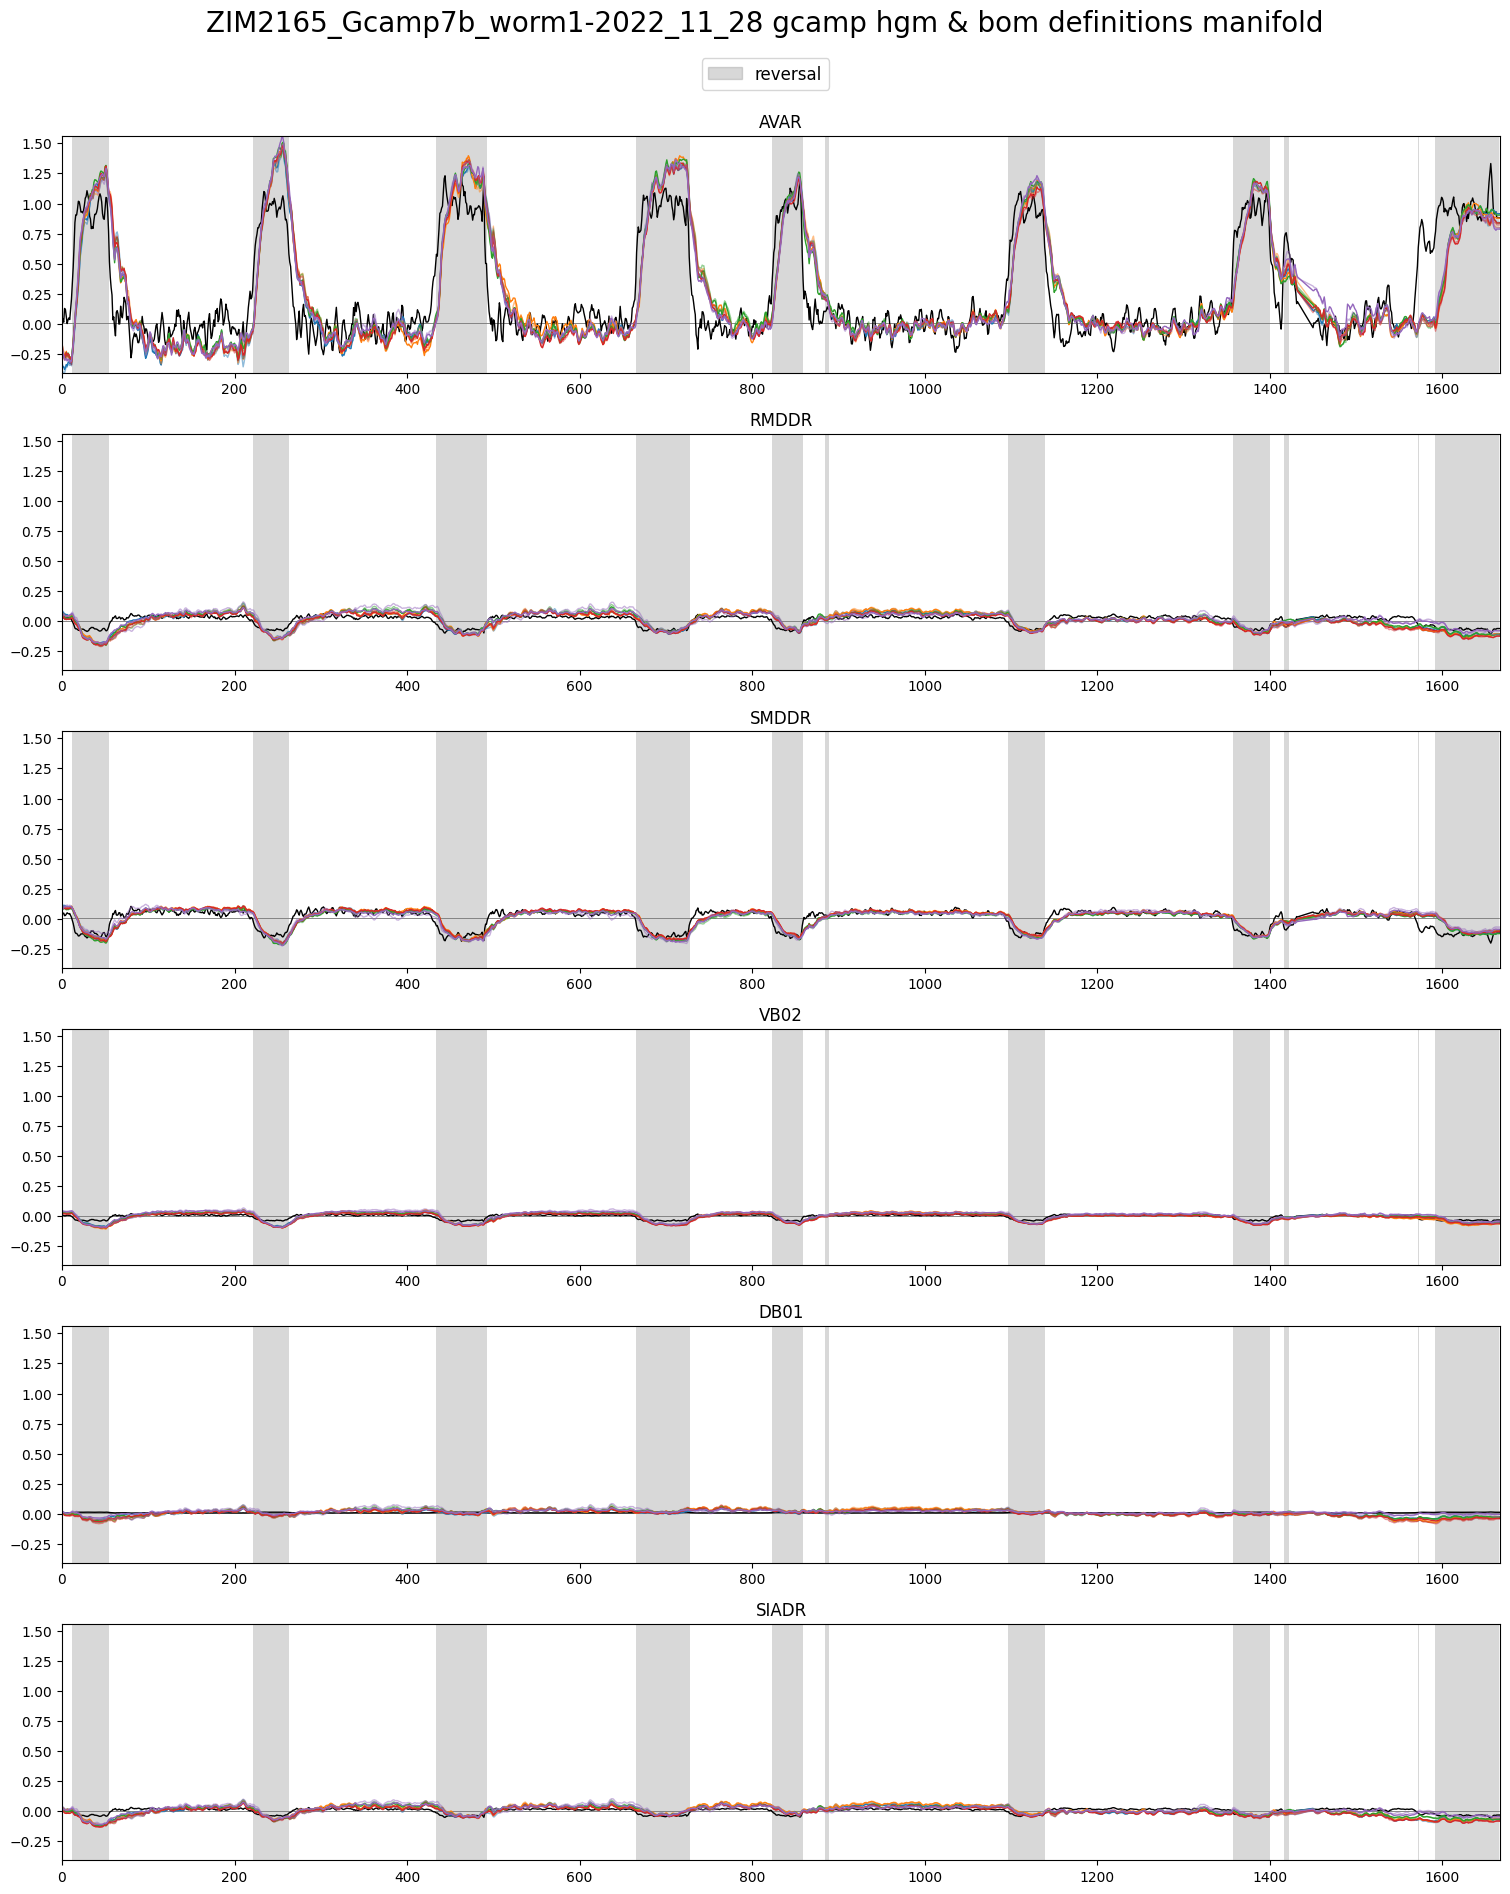

In [318]:
if gcamp:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_rec_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		traces_cca_rec_gcamp[file_ids_gcamp.index(plot_id_gcamp)][selection_n_traces_gcamp],
		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']], label='reversal',
		title=f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/GCAMP_MAN'

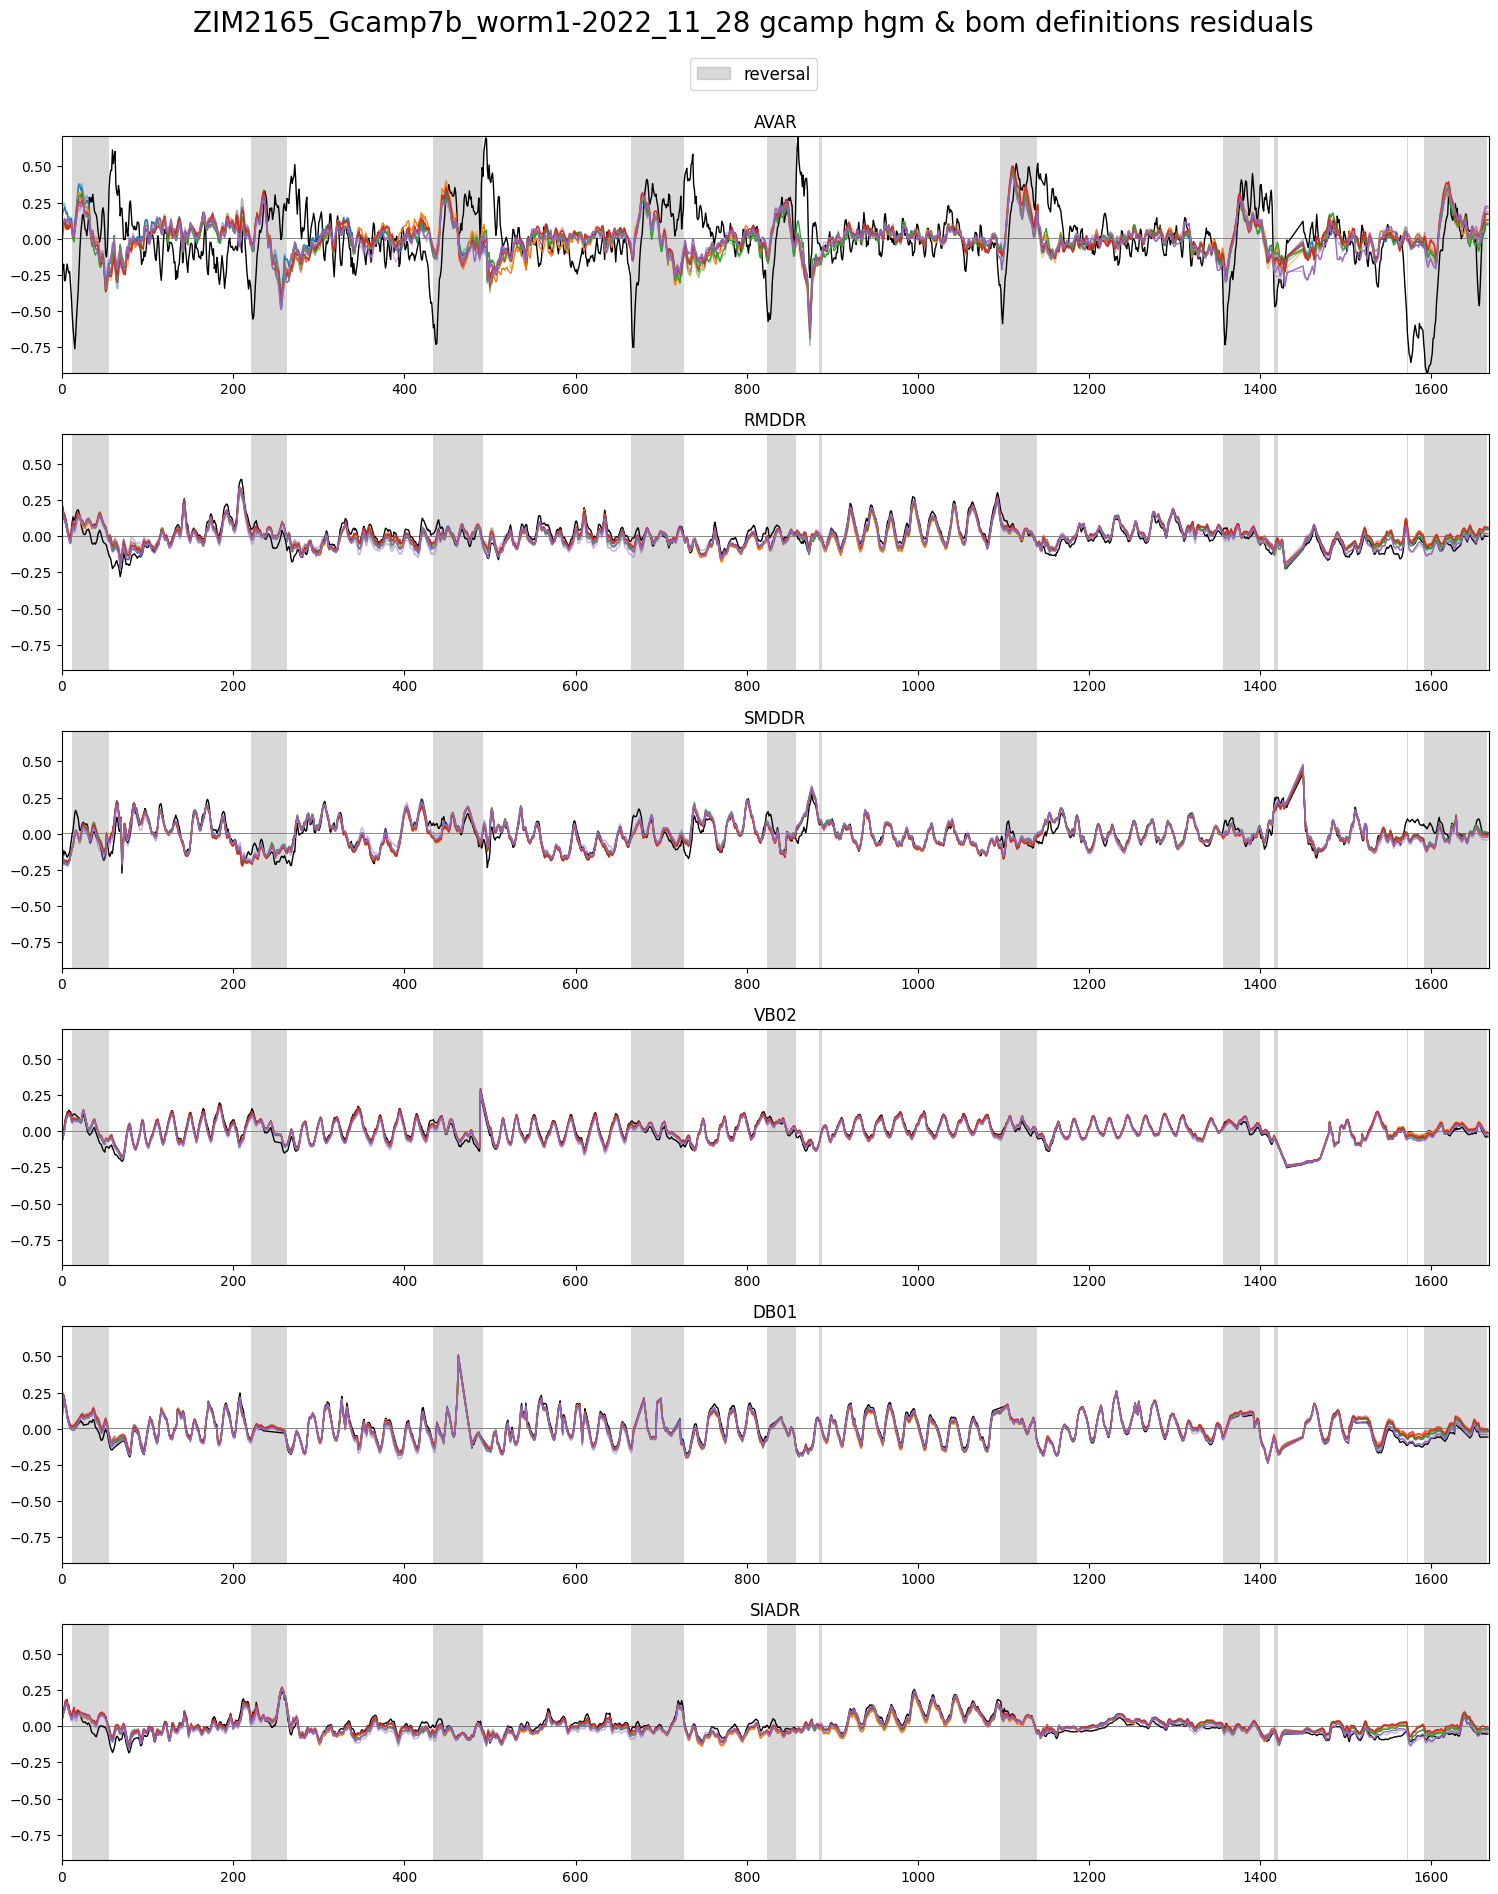

In [345]:
if gcamp:
	splits = 5
	plot_utils.plot_traces_splits(
		[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp] for i in range(splits)],
		traces_cca_res_gcamp[file_ids_gcamp.index(plot_id_gcamp)][selection_n_traces_gcamp],
		discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']], label='reversal',
		title=f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #'../../out/plots/GCAMP_MAN'

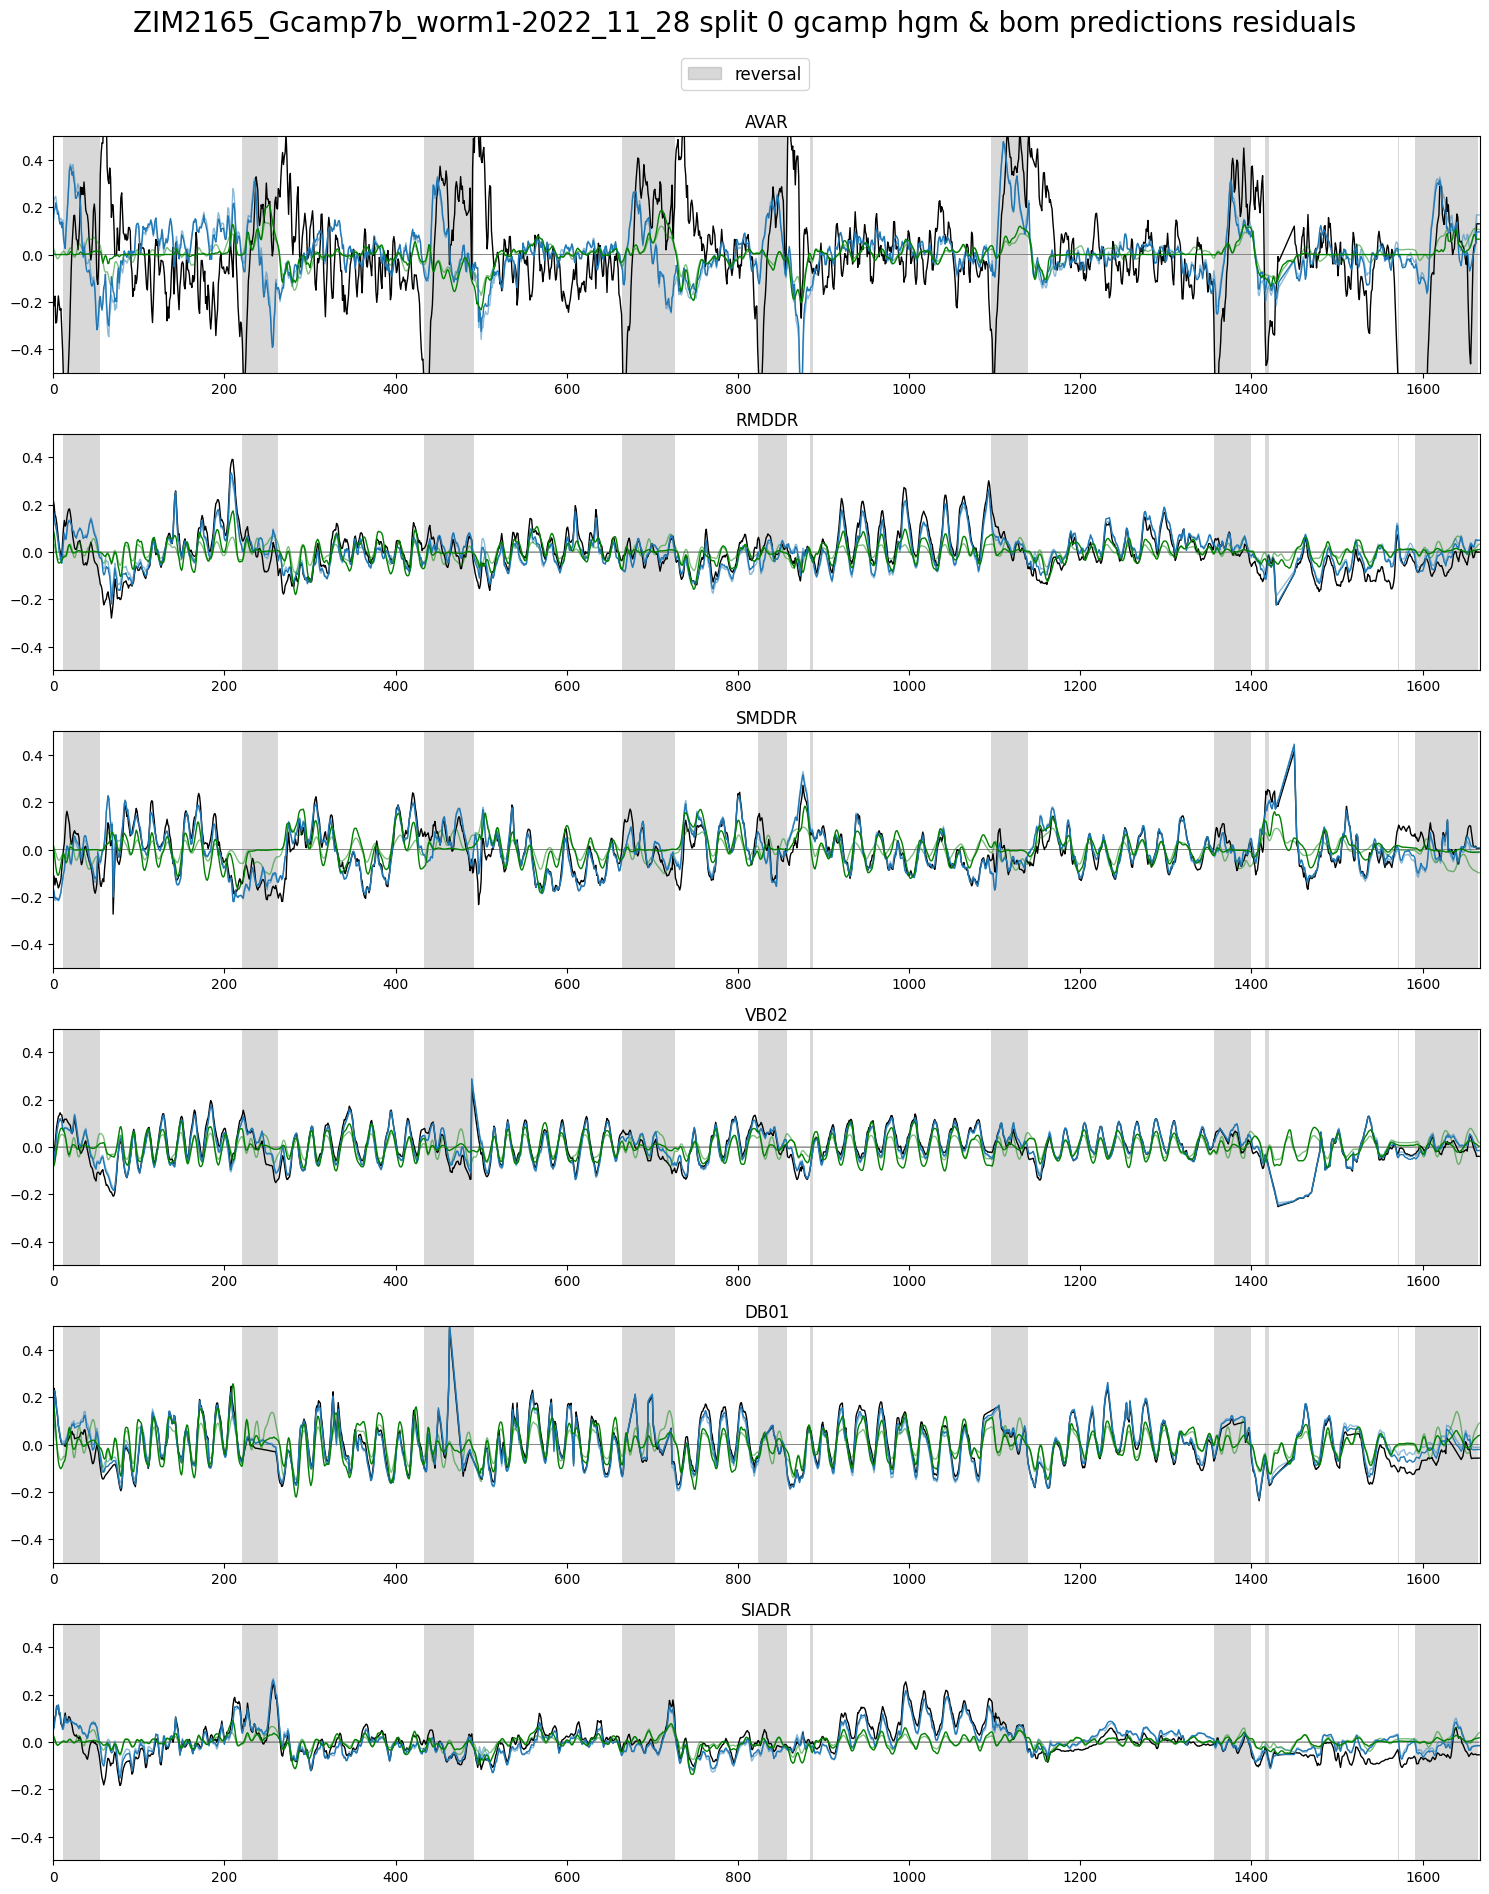

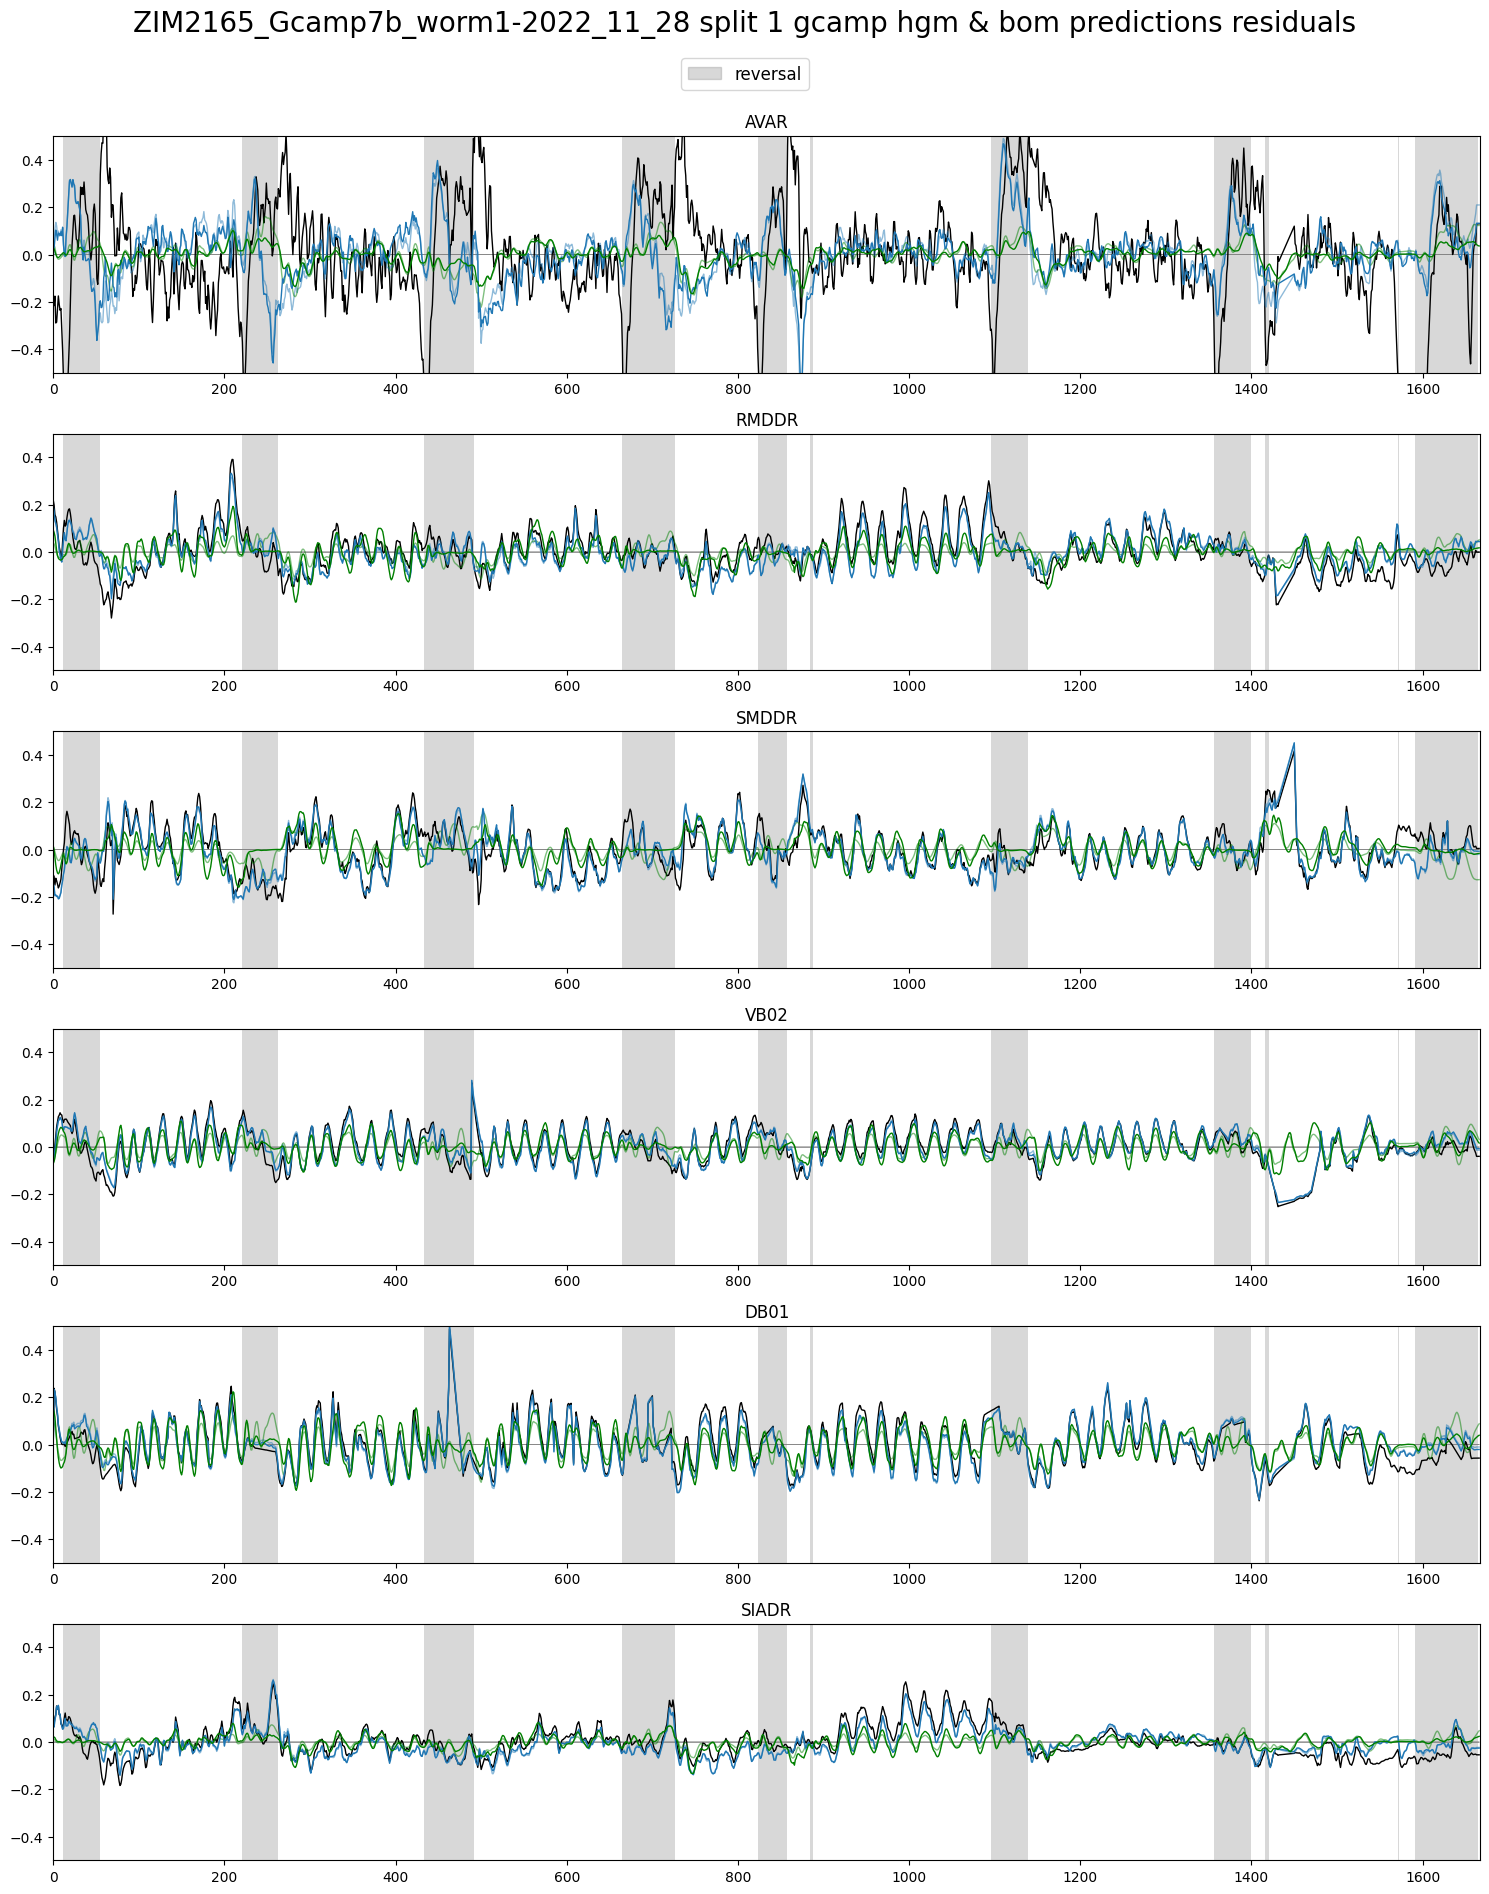

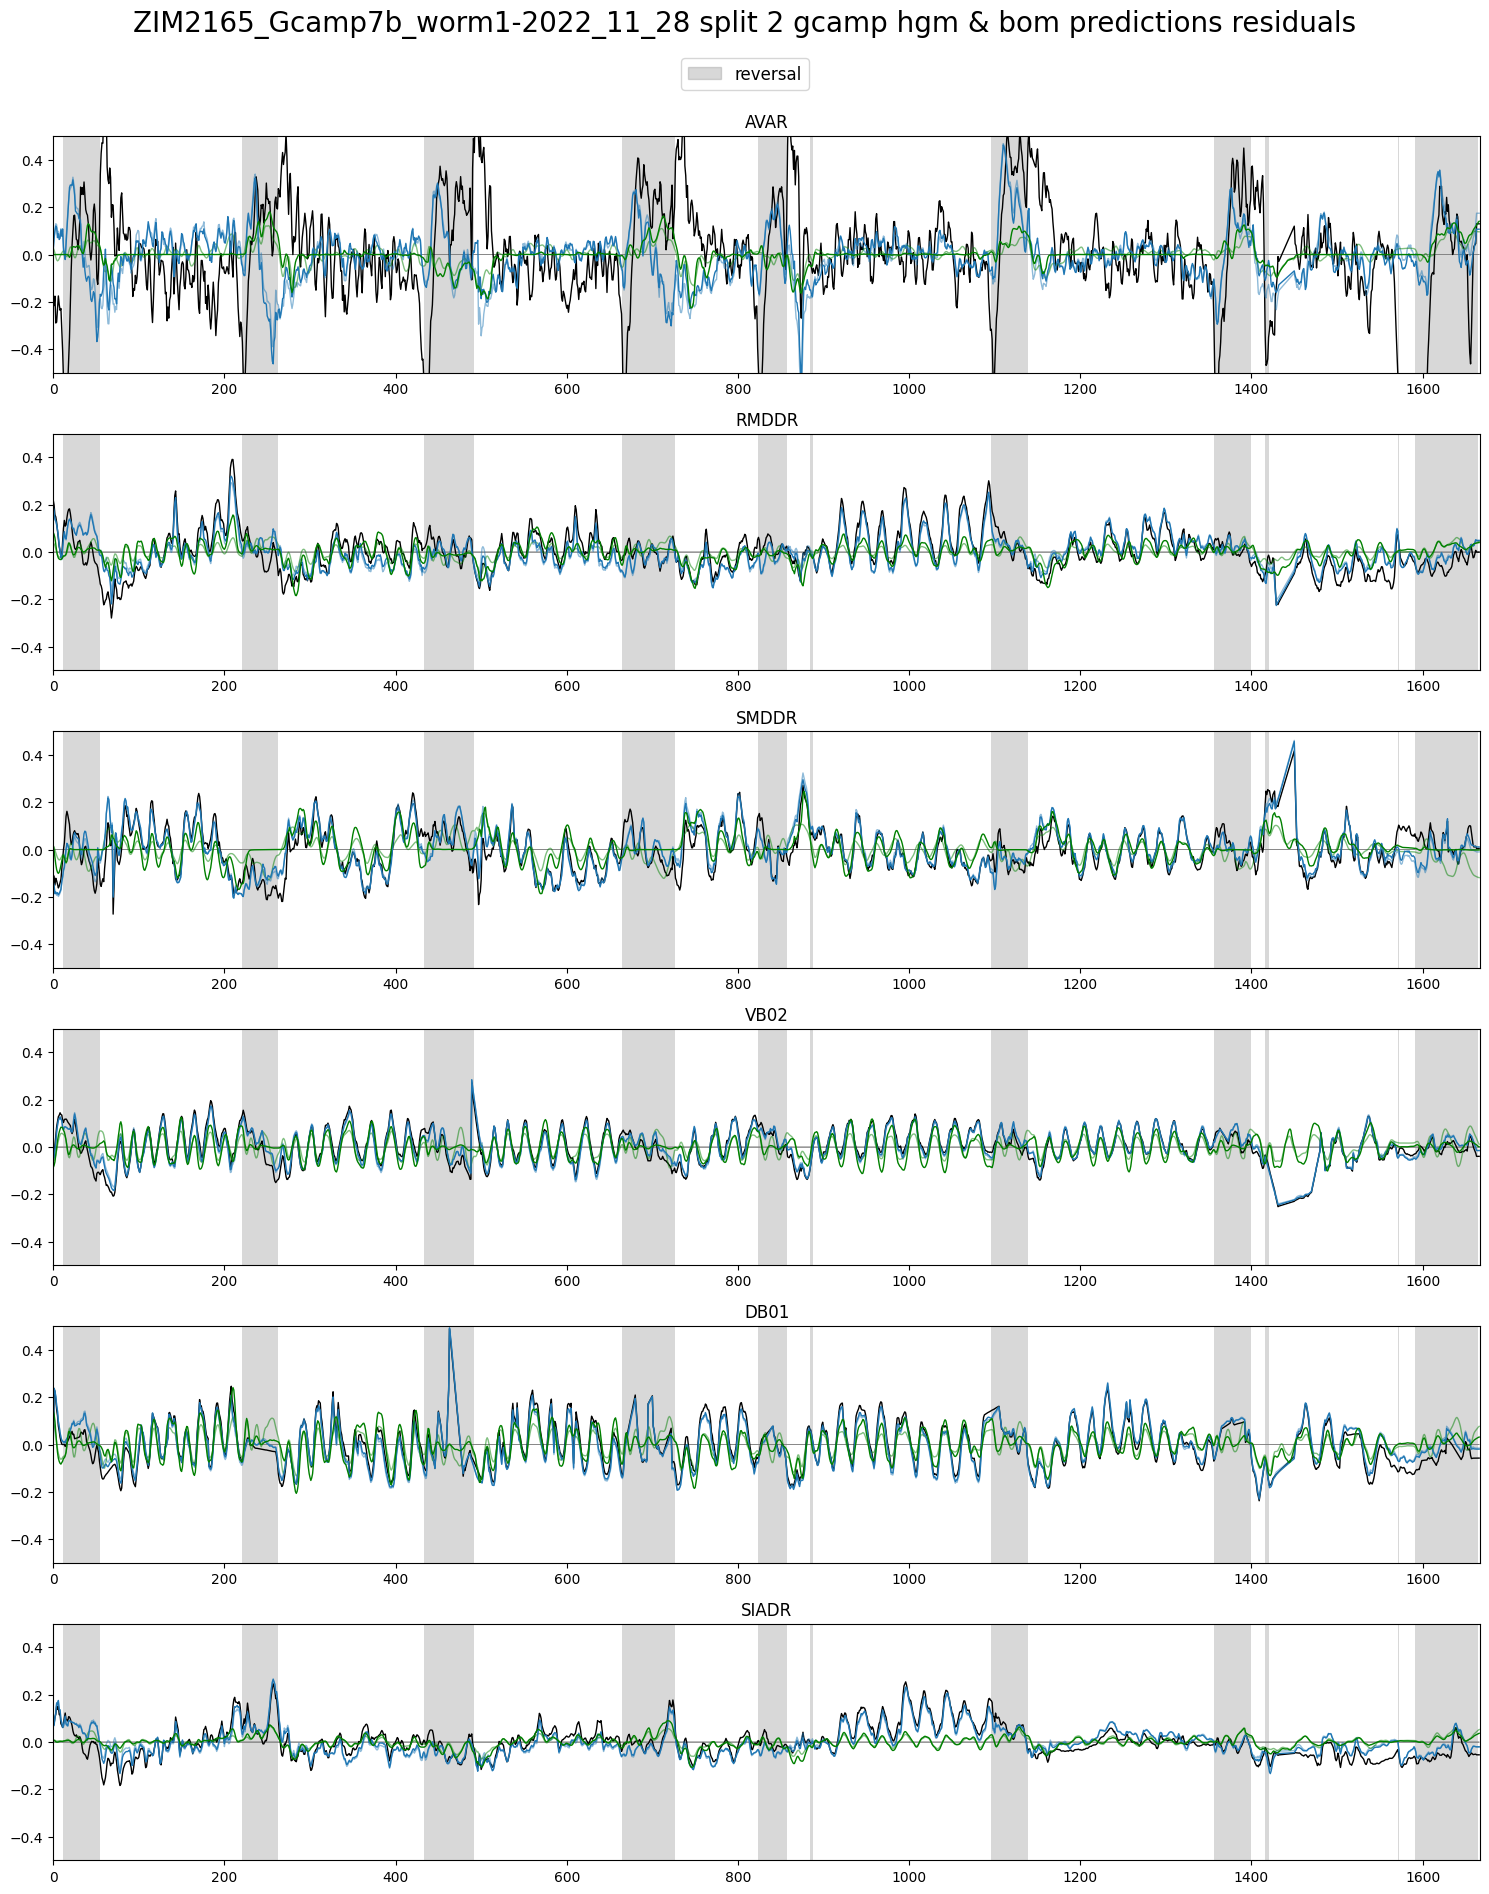

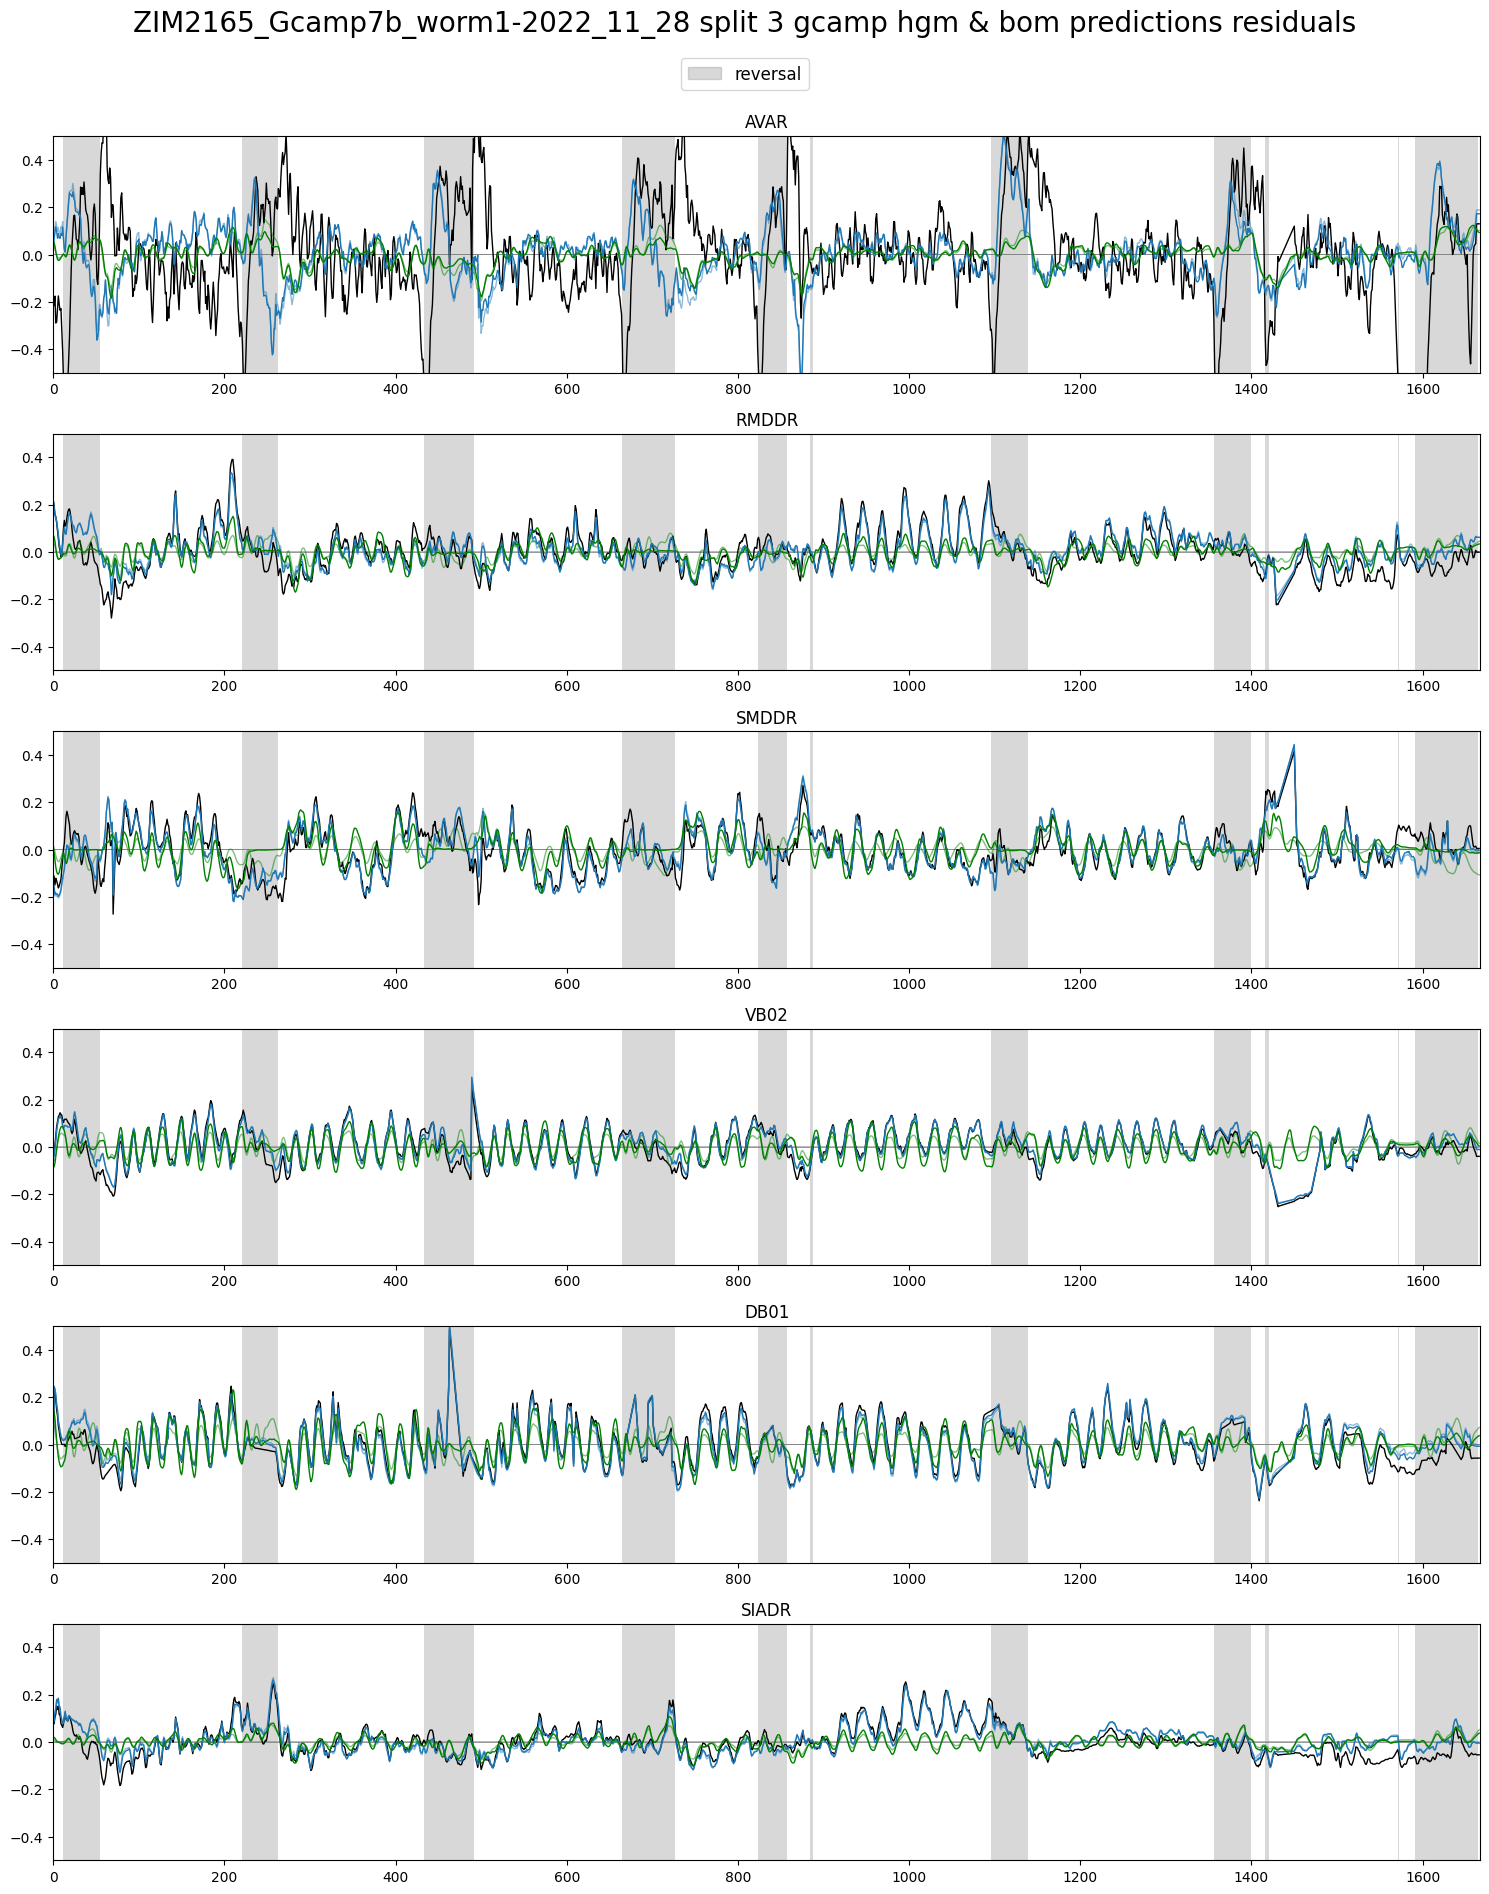

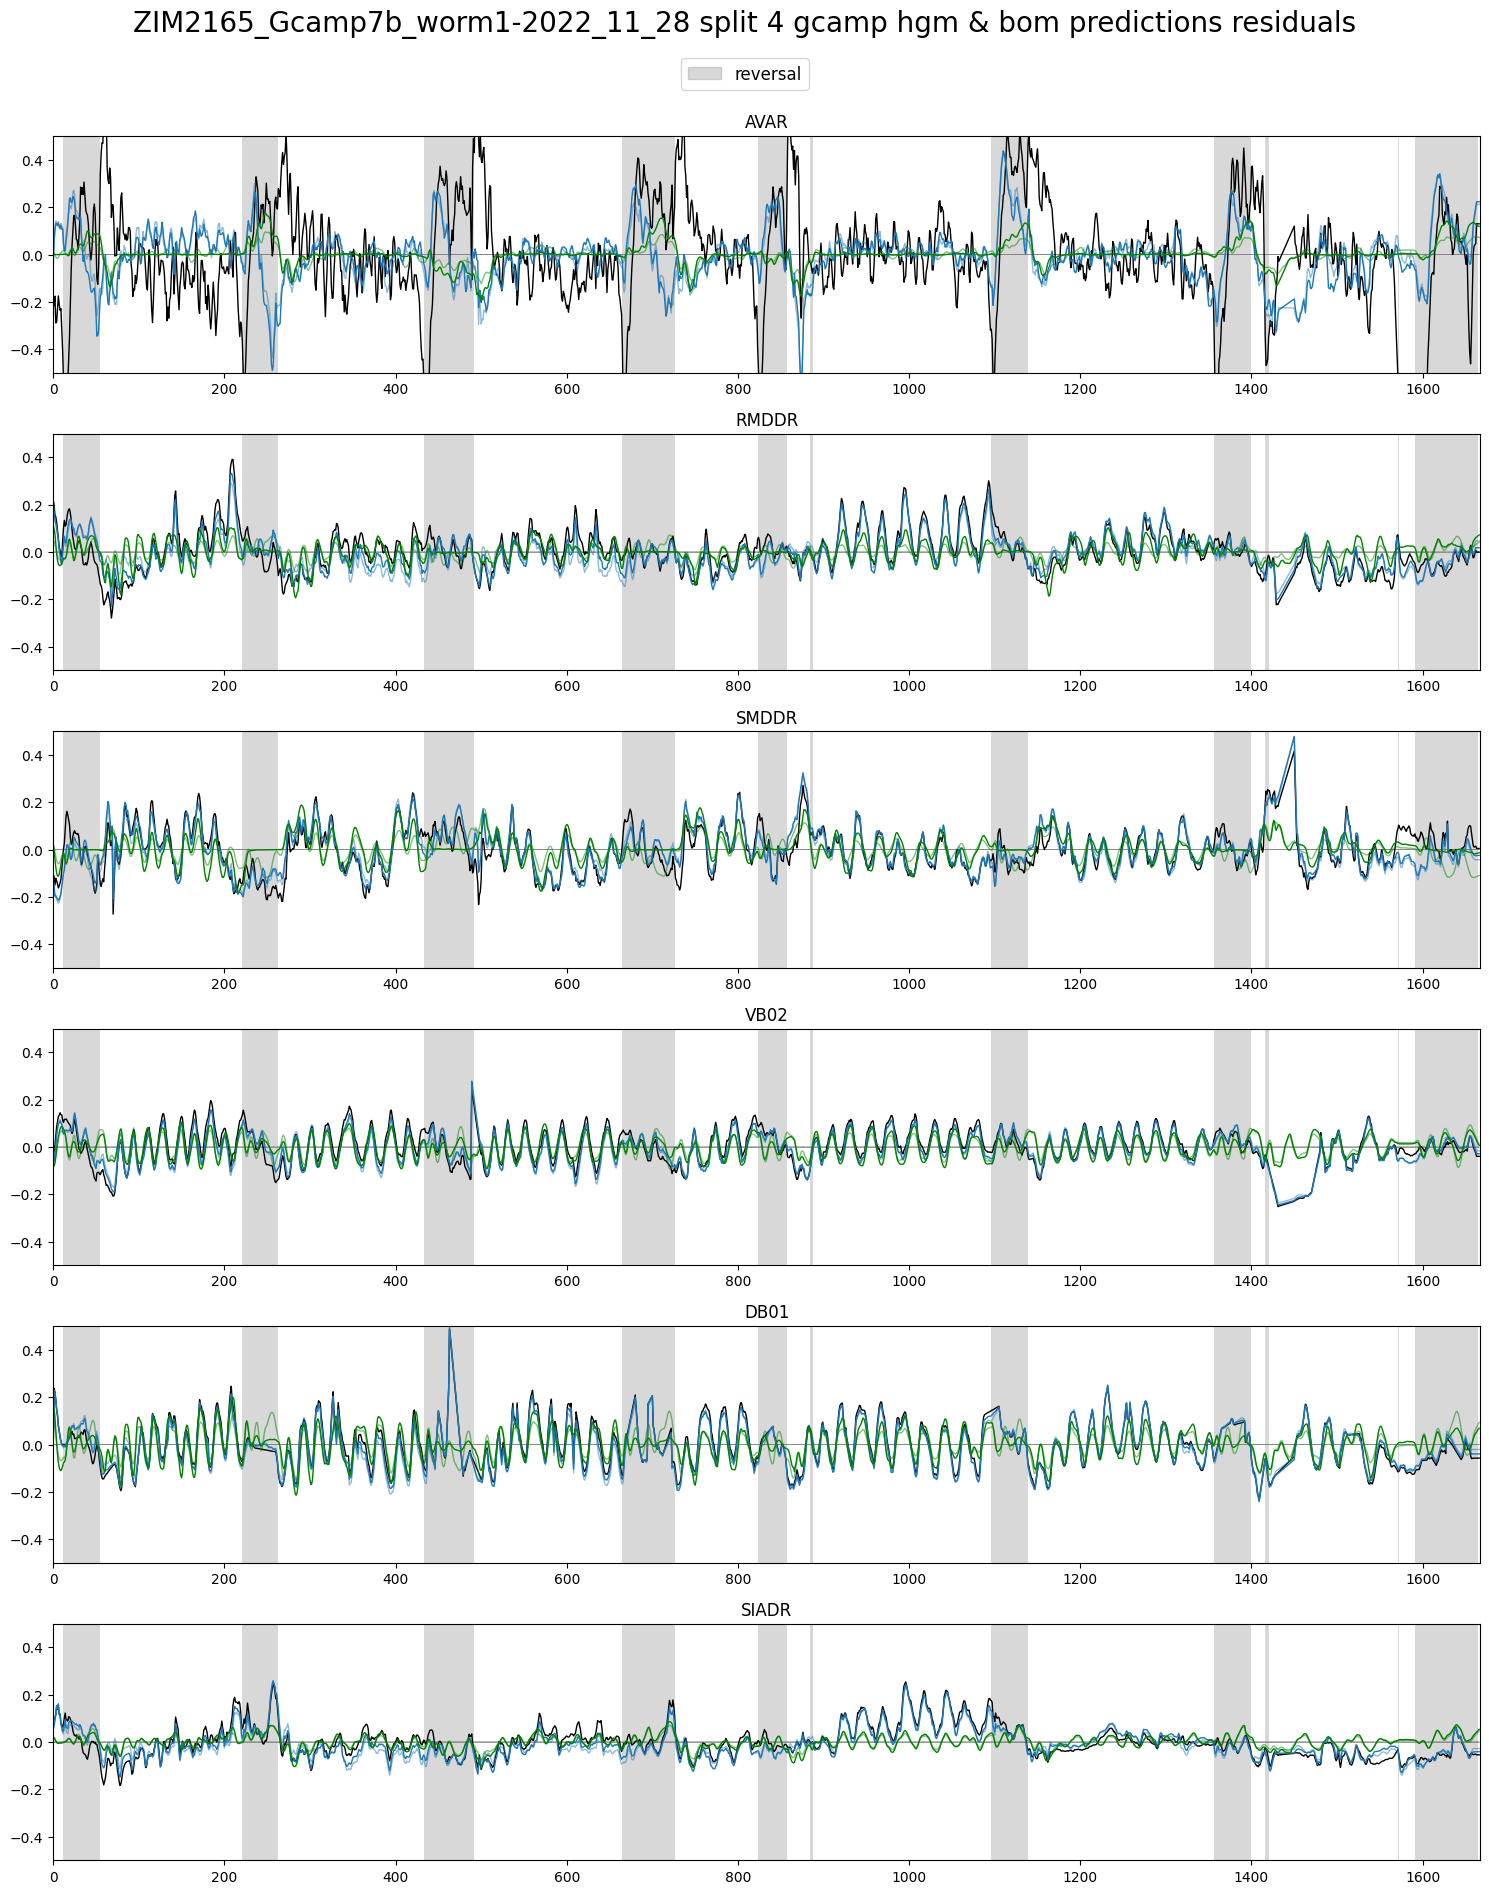

In [320]:
if gcamp:
	for i in range(5):
		plot_utils.plot_traces_splits_pairs(
			[hgms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp],
			 hgms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp]],
			[boms_res_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp],
			 boms_pres_gcamp_full[file_ids_gcamp.index(plot_id_gcamp)][i][selection_n_traces_gcamp]],
			traces_cca_res_gcamp[file_ids_gcamp.index(plot_id_gcamp)][selection_n_traces_gcamp],
			discrete_states_gcamp[file_ids_gcamp.index(plot_id_gcamp)][['REV']], label='reversal',
			title=f'{filenames_gcamp[file_ids_gcamp.index(plot_id_gcamp)]} split {i} gcamp hgm & bom predictions residuals', ylimits=(-0.5, 0.5), plots_per_row=1,
			save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

# gfp

### predict & score

In [321]:
if gfp:
	splits_gfp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i][['REV']].values)) for i in range(len(file_ids_gfp))]

In [322]:
if gfp:
	boms_spn_man_rec_res_pres_gfp = [[
		bom.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(boms_params_gfp[i], splits_gfp[i])
	] for i in range(len(file_ids_gfp))]

	hgms_spn_man_rec_res_pres_gfp = [[
		hgm.score_fn(params, traces_gfp[i].values[eval], eigenworms_gfp[i].values[eval]) for params, (train, eval) in zip(hgms_params_gfp[i], splits_gfp[i])
	] for i in range(len(file_ids_gfp))]

	(boms_spn_gfp,
	 boms_man_gfp,
	 boms_rec_gfp,
	 boms_res_gfp,
	 boms_pres_gfp) = separate_losses(file_ids_gfp, [trace.columns for trace in traces_gfp], boms_spn_man_rec_res_pres_gfp)

	(hgms_spn_gfp,
	 hgms_man_gfp,
	 hgms_rec_gfp,
	 hgms_res_gfp,
	 hgms_pres_gfp) = separate_losses(file_ids_gfp, [trace.columns for trace in traces_gfp], hgms_spn_man_rec_res_pres_gfp)

### performance

In [323]:
if gfp:
	neuron_scores_gfp = assemble(boms_spn_gfp, hgms_spn_gfp)

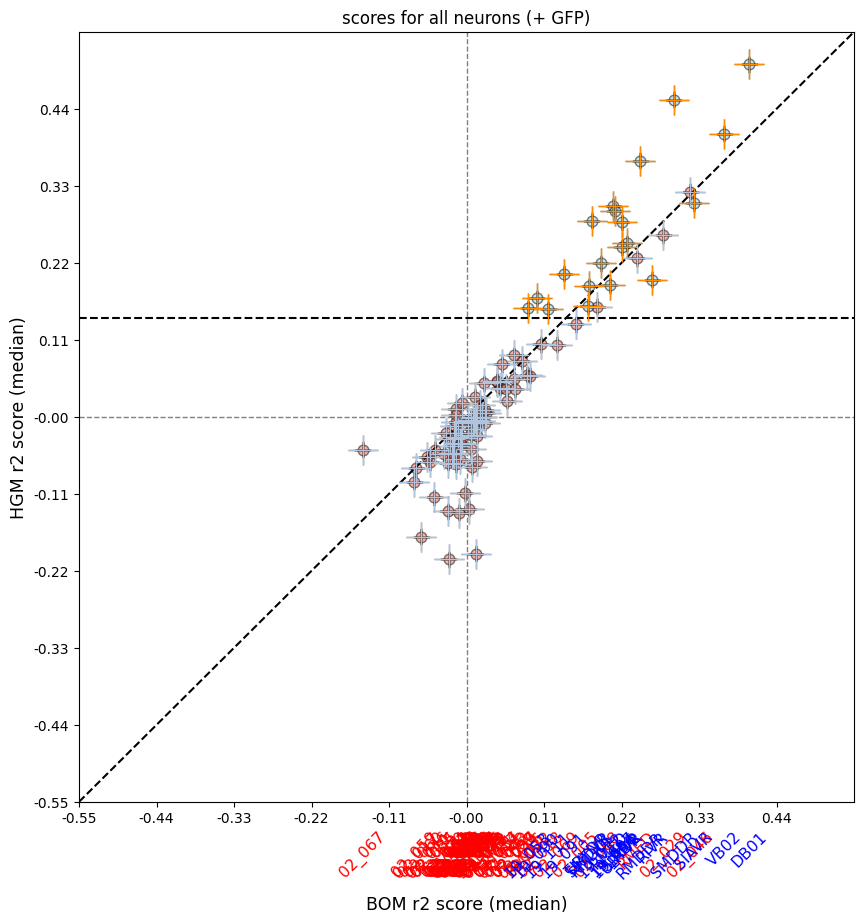

In [324]:
if gcamp and gfp:
	plot_utils.plot_performance_plot(
		neuron_scores_gcamp, neuron_scores_gfp,
		title='scores for all neurons (+ GFP)', limits=(-0.55, 0.55, -0.55, 0.55), force_medians=True
	)

In [325]:
if gcamp and gfp:
	high_score_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)

	selection_n_hgmssig = list()
	for key in neuron_scores_gcamp.keys():
		scores_bom, scores_hgm = neuron_scores_gcamp[key]
		if len(scores_hgm.shape) == 0:
			scores_bom = scores_bom.reshape(1, 1)
			scores_hgm = scores_hgm.reshape(1, 1)
		y = np.median(scores_hgm)
		if y > high_score_hgm_gfp:
			selection_n_hgmssig.append(key)

In [326]:
# if gcamp and gfp:
# 	neuron_imprsig_gcamp = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys()}
# 	selection_n_imprsig = [key for _, key in reversed(sorted(zip(neuron_imprsig_gcamp.values(), neuron_imprsig_gcamp.keys())))]

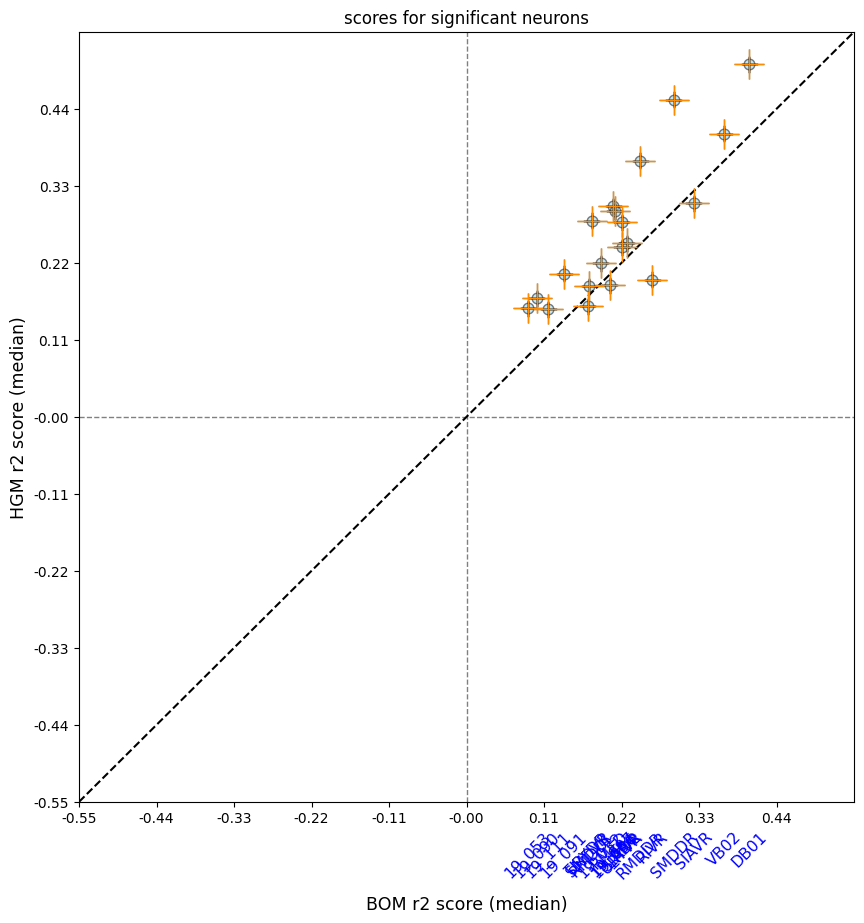

In [327]:
if gcamp and gfp:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys()}, None,
		title='scores for significant neurons', limits=(-0.55, 0.55, -0.55, 0.55), force_medians=True
	)

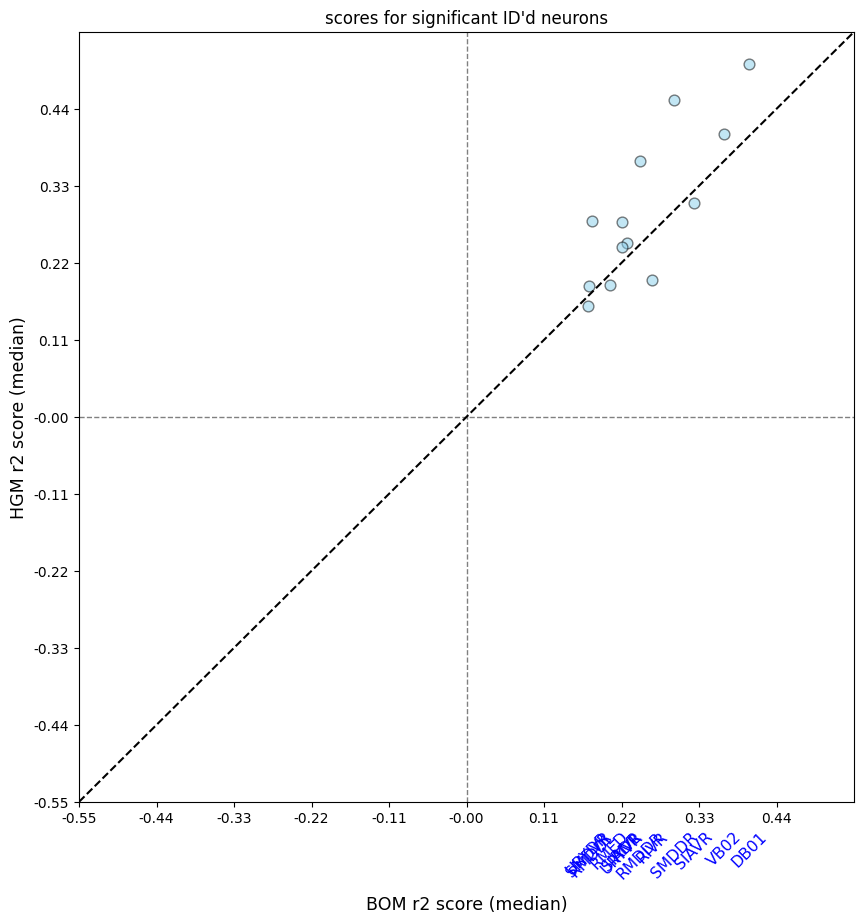

In [328]:
if gcamp and gfp:
	plot_utils.plot_performance_plot(
		{key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys() and not key[0].isdigit()}, None,
		title='scores for significant ID\'d neurons', limits=(-0.55, 0.55, -0.55, 0.55))

In [329]:
if gcamp and gfp:
	print('\n'.join([f'NEURON: {key},\tHGM: {np.median(val[1]):.4f}\tBOM: {np.median(val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1]))) if key in selection_n_hgmssig and not key[0].isdigit()]))

NEURON: DB01,	HGM: 0.5040	BOM: 0.4010
NEURON: SMDDR,	HGM: 0.4530	BOM: 0.2944
NEURON: VB02,	HGM: 0.4044	BOM: 0.3657
NEURON: RMDDR,	HGM: 0.3660	BOM: 0.2469
NEURON: SIAVR,	HGM: 0.3050	BOM: 0.3224
NEURON: RMDDL,	HGM: 0.2803	BOM: 0.1780
NEURON: SIADR,	HGM: 0.2777	BOM: 0.2204
NEURON: RIVL,	HGM: 0.2479	BOM: 0.2271
NEURON: URYVR,	HGM: 0.2420	BOM: 0.2204
NEURON: RIVR,	HGM: 0.1956	BOM: 0.2635
NEURON: RMED,	HGM: 0.1877	BOM: 0.2030
NEURON: SMDVR,	HGM: 0.1867	BOM: 0.1743
NEURON: URYDR,	HGM: 0.1578	BOM: 0.1719


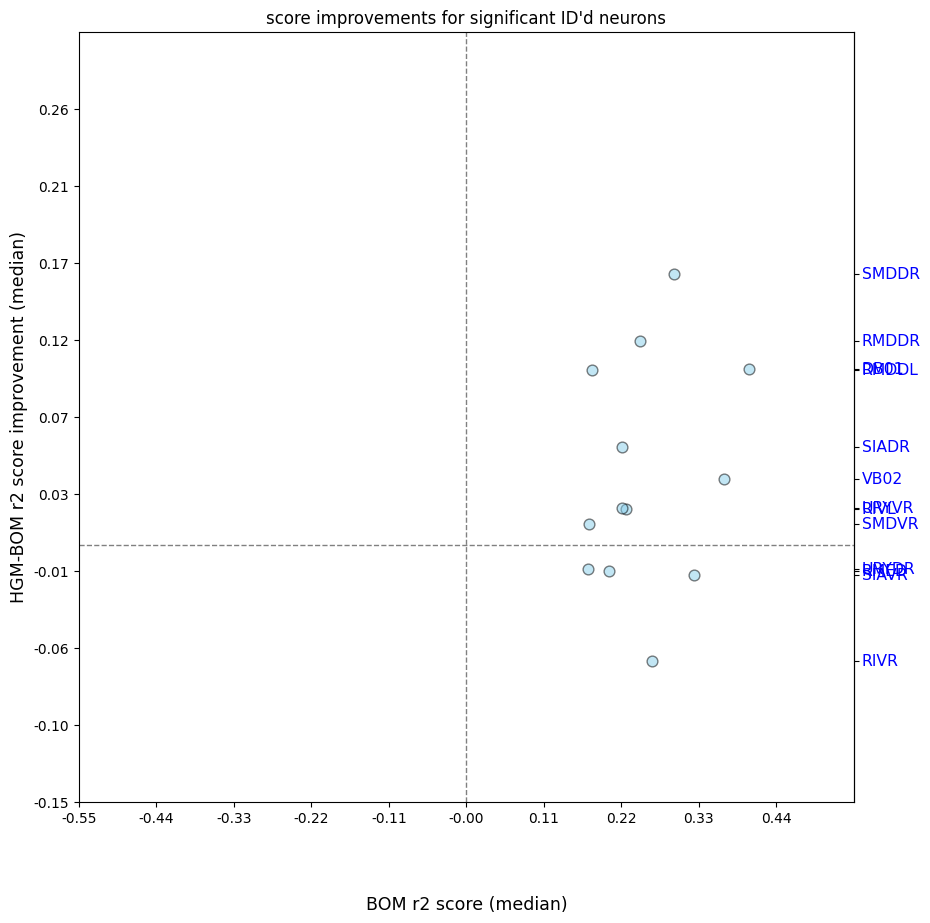

In [330]:
if gcamp and gfp:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys() and not key[0].isdigit()}, None,
		title='score improvements for significant ID\'d neurons', limits=(-0.55, 0.55, -0.15, 0.30))

In [331]:
if gcamp and gfp:
	print('\n'.join([f'NEURON: {key},\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in reversed(sorted(neuron_scores_gcamp.items(), key=lambda x: np.median(x[1][1] - x[1][0]))) if key in selection_n_hgmssig and not key[0].isdigit()]))

NEURON: SMDDR,	IMPR: 0.1586
NEURON: RMDDR,	IMPR: 0.1191
NEURON: DB01,	IMPR: 0.1030
NEURON: RMDDL,	IMPR: 0.1023
NEURON: SIADR,	IMPR: 0.0573
NEURON: VB02,	IMPR: 0.0388
NEURON: URYVR,	IMPR: 0.0216
NEURON: RIVL,	IMPR: 0.0209
NEURON: SMDVR,	IMPR: 0.0124
NEURON: URYDR,	IMPR: -0.0141
NEURON: RMED,	IMPR: -0.0154
NEURON: SIAVR,	IMPR: -0.0174
NEURON: RIVR,	IMPR: -0.0678


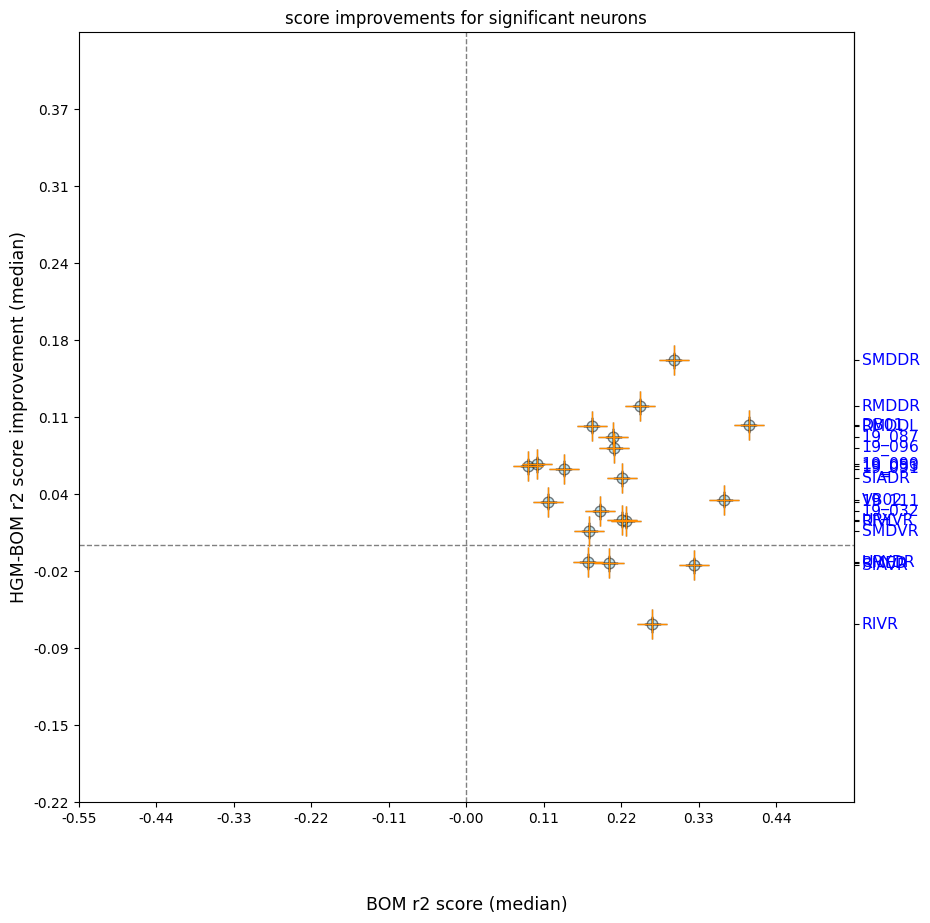

In [332]:
if gcamp and gfp:
	plot_utils.plot_improvement_plot(
		{key: neuron_scores_gcamp[key] for key in selection_n_hgmssig if key in neuron_scores_gcamp.keys()},
		title='score improvements for significant neurons', limits=(-0.55, 0.55, -0.22, 0.44), force_medians=True)